# NYC Yellow Taxi 2015–2016 — Model-Based Anomaly Detection

In Task 3 I built a statistical baseline: univariate MAD bounds, segment-wise robust Mahalanobis distance and time-series methods on the hourly series. In this notebook I applied model-based methods to the same feature matrix and compared their results with each other and with the Task 3 outputs. The core question was: do the models catch something the statistics cannot see, and if so, at what cost?

The data has no ground truth, so I did not answer "which model is better" with a single metric. I used three kinds of evidence: errors I deliberately injected into the data, a real and previously known error in the data (the daylight saving time transition), and a tariff-based labelling rule applied to the flagged trips. Each has a weakness; I describe them in the relevant sections.

The notebook runs on the saved models. With `RECOMPUTE = False` the models are loaded from disk; with `True` they are retrained with the same settings. In every section the table or plot that supports a decision comes before the text that explains it.

## 0. Summary

- I applied six model-based methods (Isolation Forest, LOF, One-Class SVM, two XGBoost residual models, an autoencoder), an LSTM autoencoder and five open-source methods from the literature. The models split into two families: those that look at density and geometry (IF, LOF, OCSVM) and those that look at the deviation from "the expected value for this trip" (XGBoost and the autoencoder). The second family proved clearly more useful on this data.
- The main gain over Task 3 is on small and conditional anomalies. On the untouched E3 set, the consensus score of XGBoost fare and the autoencoder caught a fare inflated by only $5 85.0 points more often than the Task 3 union flag, and a duration extended by 15 minutes 83.6 points more often. The autoencoder ensemble I recommend is ahead of Task 3 on its own in at least six of the seven small-error variants (mean +33.2 points). On large errors ($25, 60 minutes) the two approaches are equal. The models counted legitimate congestion as anomalous much less often (difference −90.6 points for the autoencoder ensemble); this is a tolerance difference: once a tariff-consistent delay reaches 45 minutes, the autoencoder flags it too.
- Where the models lose is also clear: a tip multiplied by five (Task 3 68.4, models at most 2.6), a consistent long detour that needs route information, and a phantom toll. I therefore recommend adding the models next to the Task 2 rules and the Task 3 tip flag, not replacing them.
- Manual inspection: I looked at the raw records of each model's top 10 trips. The top 10 of LOF, OCSVM, XGBoost and the autoencoder consist almost entirely of real billing and data errors; half of the Isolation Forest top 10 are legitimate trips. Agreement between the labelling rule and my own blind labels was weak (κ = 0.26), so I read the rule-based precision figures as indicative.
- On the business side there is no single "best model"; the choice depends on the budget. With a narrow budget of about 390 alarms per day (0.1%), the autoencoder ensemble gave the highest real-anomaly share (56.5% on E3; the confidence intervals overlap, so the decision at this budget rests mainly on the 13.0-point difference on small errors). With a wide budget of about 3,900 alarms per day (1%), XGBoost catches small errors better, but 17.4% of its queue is legitimate congestion. Computation is cheap (about 12 seconds per million trips); the real cost is monitoring and monthly recalibration.

### Contents: questions and where they are answered

| Topic | Section |
|---|---|
| At least 5 model-based methods, comparison with Task 3 | 3, 5 |
| 1) Model choice and how each model works | 3 (one subsection per model) |
| 2) Implementation, hyperparameter rationale, effect of contamination | 3.2–3.10 |
| 3) Comparison of the models with each other | 4 |
| 4) Comparison with the statistical methods: where we won, where we lost | 5 |
| 5) Manual inspection of anomaly examples | 6 |
| 6) Robustness: different months, regions | 7 |
| 7) Business view: which model, is the complexity worth it, production errors and monitoring | 8 |
| Open-source model from the literature (extra) | 3.11, Appendix D |
| Findings & next steps | 9 |
| Additional analyses | 10 |

## 1. Setup and reproducibility

In the setup cell I loaded the libraries and defined the folders. I ran the long computations (retraining, the E3–E6 tests, injection sweeps) in a separate computation notebook and saved their results as CSV files under `artifacts/task4/k28/`; this notebook reads those files and checks them against live computations with the saved models. I recorded the library versions used to produce the saved models and artifacts in `manifest.json`. The table below compares the versions in this kernel with the recorded ones. Scores can change when scikit-learn and XGBoost models are loaded under a different version, so this check comes first.

In [1]:
import hashlib
import json
import importlib.metadata as md
import platform
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xgboost as xgb
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import matplotlib.dates as mdates
import shap

PROJECT_ROOT = Path.cwd().parent
TASK4_DIR = PROJECT_ROOT / "artifacts" / "task4"
K28_DIR = TASK4_DIR / "k28"
MODEL_DIR = K28_DIR / "models"
STATE_DIR = TASK4_DIR / "_kontrol_state"
RECOMPUTE = False  # True retrains the six models on training pool A (about 10 min on 4 CPU cores); False loads the saved models

torch.set_num_threads(4)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

GREY, RED, BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#9a9a96", "#e34948", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold"})

manifest = json.loads((K28_DIR / "manifest.json").read_text(encoding="utf-8"))
versions = pd.DataFrame(
    [{"package": "python", "saved": manifest["python"], "this kernel": platform.python_version()}]
    + [{"package": p, "saved": v, "this kernel": md.version(p) if p != "pyod" else "not needed"}
       for p, v in manifest["packages"].items()])
versions["same"] = [k == "not needed" or s.split("+")[0] == k.split("+")[0] or (p == "python" and s[:4] == k[:4])
                    for p, s, k in zip(versions["package"], versions["saved"], versions["this kernel"])]
versions

,package,saved,this kernel,same
0,python,3.11.9,3.11.9,True
1,numpy,2.4.6,2.4.6,True
2,pandas,3.0.5,3.0.5,True
3,scipy,1.17.1,1.17.1,True
4,scikit-learn,1.9.1,1.9.1,True
5,duckdb,1.5.5,1.5.5,True
6,pyarrow,25.0.1,25.0.1,True
7,xgboost,3.2.0,3.2.0,True
8,torch,2.14.1+cpu,2.14.1+cpu,True
9,shap,0.51.0,0.51.0,True


All versions match the recorded ones (for Python I compared only the major and minor version). pyod was needed only to train the literature models; this notebook reads their saved results.

To show that the model files have not changed since they were saved, I compared the SHA-256 digest of each file with the value in the manifest. If a single file differs, the cell stops with an error.

In [2]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

sha_rows = [{"file": name, "match": (K28_DIR / name).exists() and sha256(K28_DIR / name) == expected}
            for name, expected in manifest["sha256"].items()]
sha_check = pd.DataFrame(sha_rows)
assert sha_check["match"].all(), sha_check.loc[~sha_check["match"], "file"].tolist()
pd.DataFrame({"model files in manifest": [len(sha_check)], "SHA-256 identical": [int(sha_check["match"].sum())]})

,model files in manifest,SHA-256 identical
0,33,33


All 33 model files are exactly as saved.

Next I loaded the data used in the evaluation: the model input of the E2 subset (107,518 trips, 74 columns), the 14 injection variants placed in this subset, the 8,989 trips corrupted by the daylight saving time transition, and the 100,000-row calibration set on which the thresholds are computed. Section 2 explains how the sets were split.

The next cell defines the six models and the three-seed autoencoder ensemble. The training functions and hyperparameters are in the same cell; with `RECOMPUTE = True` the models are retrained with the same settings on training pool A.

In [3]:
state = joblib.load(STATE_DIR / "kontrol_state.joblib")["settings"]
arrays = joblib.load(K28_DIR / "session_state" / "arrays.joblib")
thresholds = json.loads((K28_DIR / "thresholds.json").read_text(encoding="utf-8"))
config = json.loads((K28_DIR / "config.json").read_text(encoding="utf-8"))

MODEL_COLUMNS = state["model_columns"]
BINARY_MASK = state["binary_mask"]
NUMERIC_IDX = np.flatnonzero(~BINARY_MASK)
MEASUREMENT_COLUMNS = state["measurement_columns"]
MEASUREMENT_MASK = np.isin(MODEL_COLUMNS, MEASUREMENT_COLUMNS)
XGB_FARE_COLS, DURATION_COLS, DURATION_COL = state["xgb_cols"], state["duration_cols"], state["duration_col"]

X2, y2 = arrays["X2"], arrays["y2"]            # E2 bucket, model input (74 columns) and log1p(fare)
rule_e2, seg_e2 = arrays["rule_e2"], arrays["seg2"]
saved_e2, saved_calib = arrays["e2_sc"], arrays["calib_sc"]
inj_e2 = arrays["inj_cache"]                   # variant -> (source row index in E2, injected X, injected y)
X_dst, y_dst = arrays["Xd"], arrays["yd"]      # all DST spring-forward trips of the fit window

pd.DataFrame({"object": ["E2 rows x columns", "injected variants x rows", "DST trips", "calibration rows"],
              "value": [f"{X2.shape[0]:,} x {X2.shape[1]}", f"{len(inj_e2)} x {len(next(iter(inj_e2.values()))[0]):,}",
                        f"{len(X_dst):,}", f"{len(saved_calib['AE']):,}"]})

,object,value
0,E2 rows x columns,"107,518 x 74"
1,injected variants x rows,"14 x 1,000"
2,DST trips,"8,989"
3,calibration rows,"100,000"


In [4]:
def make_autoencoder(n_features=74):
    return torch.nn.Sequential(
        torch.nn.Linear(n_features, 48), torch.nn.ReLU(),
        torch.nn.Linear(48, 16), torch.nn.ReLU(),
        torch.nn.Linear(16, 48), torch.nn.ReLU(),
        torch.nn.Linear(48, n_features))

def load_autoencoder(name):
    model = make_autoencoder()
    model.load_state_dict(torch.load(MODEL_DIR / name))
    return model.eval()

def ae_measure(model, X):
    """Mean squared reconstruction error over the six trip-measurement columns."""
    with torch.no_grad():
        t = torch.from_numpy(np.ascontiguousarray(X))
        return ((model(t) - t) ** 2)[:, torch.from_numpy(MEASUREMENT_MASK)].mean(dim=1).numpy()

RANDOM_SEED = 42
XGB_FARE_PARAMS = {"objective": "reg:squarederror", "max_depth": 6, "learning_rate": 0.05, "min_child_weight": 50,
                   "subsample": 0.8, "colsample_bytree": 0.8}
XGB_DURATION_PARAMS = {"objective": "reg:pseudohubererror", "huber_slope": 0.5, "max_depth": 4, "learning_rate": 0.1,
                       "min_child_weight": 200, "subsample": 0.8, "colsample_bytree": 0.8}

def train_xgb(X, y, cols, params, cap, seed=RANDOM_SEED):
    """First 10% of the training rows is the early-stopping validation set."""
    n_val = len(X) // 10
    model = xgb.XGBRegressor(tree_method="hist", n_jobs=4, random_state=seed, n_estimators=cap, early_stopping_rounds=50, **params)
    model.fit(X[n_val:][:, cols], y[n_val:], eval_set=[(X[:n_val][:, cols], y[:n_val])], verbose=False)
    return model

def train_ae(X, seed=RANDOM_SEED, rel_delta=1e-3, max_epochs=200, patience=8, batch_size=1024):
    """Adam + ReduceLROnPlateau; stops when the validation MSE has not improved by 0.1% for 8 epochs."""
    torch.manual_seed(seed)
    model = make_autoencoder(X.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3, min_lr=1e-5)
    data = torch.from_numpy(np.ascontiguousarray(X))
    n_val = len(data) // 10
    train, val = data[n_val:], data[:n_val]
    generator = torch.Generator().manual_seed(seed)
    best_loss, best_state, waited = np.inf, None, 0
    for _ in range(max_epochs):
        model.train()
        for batch in torch.randperm(len(train), generator=generator).split(batch_size):
            optimizer.zero_grad()
            torch.nn.functional.mse_loss(model(train[batch]), train[batch]).backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = torch.nn.functional.mse_loss(model(val), val).item()
        scheduler.step(val_loss)
        if val_loss < best_loss * (1 - rel_delta):
            best_loss, waited, best_state = val_loss, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_state)
    return model.eval()

if RECOMPUTE:
    from sklearn.ensemble import IsolationForest
    from sklearn.neighbors import LocalOutlierFactor
    from sklearn.svm import OneClassSVM
    X_pool = np.load(STATE_DIR / "X_pool.npy")
    y_pool = np.load(STATE_DIR / "y_fare.npy")
    pool_a = np.load(STATE_DIR / "indices.npz")["pool_a"]
    X_a = X_pool[pool_a].copy()
    X_a[:, MODEL_COLUMNS.index("months_since_start")] = 0
    y_a = y_pool[pool_a]
    iforest = IsolationForest(n_estimators=1500, max_samples=2048, random_state=RANDOM_SEED, n_jobs=4).fit(X_a[:250_000][:, NUMERIC_IDX])
    lof = LocalOutlierFactor(n_neighbors=100, novelty=True, algorithm="brute", n_jobs=4).fit(X_a[:50_000])
    ocsvm = OneClassSVM(kernel="rbf", nu=0.01, gamma=config["OCSVM"]["gamma"]).fit(X_a[:30_000])
    xgb_fare = train_xgb(X_a[:537_000], y_a[:537_000], XGB_FARE_COLS, XGB_FARE_PARAMS, cap=2000)
    xgb_duration = train_xgb(X_a[:537_000], X_a[:537_000, DURATION_COL], DURATION_COLS, XGB_DURATION_PARAMS, cap=4000)
    ae_members = [train_ae(X_a[:250_000], seed=RANDOM_SEED + offset) for offset in (0, 100, 200)]
else:
    iforest = joblib.load(MODEL_DIR / "if_numeric.joblib")
    lof = joblib.load(MODEL_DIR / "lof.joblib")
    ocsvm = joblib.load(MODEL_DIR / "ocsvm.joblib")
    xgb_fare = xgb.XGBRegressor()
    xgb_fare.load_model(MODEL_DIR / "xgb_fare.json")
    xgb_duration = xgb.XGBRegressor()
    xgb_duration.load_model(MODEL_DIR / "xgb_duration.json")
    ae_members = [load_autoencoder(n) for n in ("ae.pt", "ae_seed_extra_100.pt", "ae_seed_extra_200.pt")]

SCORERS = {
    "IF numeric": lambda X, y: -iforest.score_samples(X[:, NUMERIC_IDX]),
    "LOF": lambda X, y: -lof.score_samples(X),
    "OCSVM": lambda X, y: -ocsvm.decision_function(X),
    "XGB fare": lambda X, y: np.abs(y - xgb_fare.predict(X[:, XGB_FARE_COLS])),
    "XGB duration": lambda X, y: np.abs(X[:, DURATION_COL] - xgb_duration.predict(X[:, DURATION_COLS])),
    "AE": lambda X, y: ae_measure(ae_members[0], X),
    "AE 3-seed ens": lambda X, y: np.mean([ae_measure(m, X) for m in ae_members], axis=0),
}
MODELS6 = ["IF numeric", "LOF", "OCSVM", "XGB fare", "XGB duration", "AE"]

pd.DataFrame({"model": list(SCORERS),
              "object": [type(iforest).__name__, type(lof).__name__, type(ocsvm).__name__, "XGBRegressor", "XGBRegressor",
                         "torch Sequential 74-48-16-48-74", "3 x torch Sequential (seeds 42, 142, 242)"],
              "score": ["-score_samples (19 numeric columns)", "-score_samples", "-decision_function",
                        "|log fare - predicted|", "|duration - predicted|", "measurement MSE", "mean of 3 measurement MSEs"]})

,model,object,score
0,IF numeric,IsolationForest,-score_samples (19 numeric columns)
1,LOF,LocalOutlierFactor,-score_samples
2,OCSVM,OneClassSVM,-decision_function
3,XGB fare,XGBRegressor,|log fare - predicted|
4,XGB duration,XGBRegressor,|duration - predicted|
5,AE,torch Sequential 74-48-16-48-74,measurement MSE
6,AE 3-seed ens,"3 x torch Sequential (seeds 42, 142, 242)",mean of 3 measurement MSEs


To show that the saved models really produce the same scores in this notebook, I scored all of E2 live and compared the results with the scores saved during model selection.

In [5]:
def calib_percentile(scores, calib):
    return np.searchsorted(np.sort(calib), scores, side="right") / len(calib)

live_e2 = {name: f(X2, y2) for name, f in SCORERS.items()}
live_e2["consensus"] = (calib_percentile(live_e2["XGB fare"], saved_calib["XGB fare"])
                        + calib_percentile(live_e2["AE"], saved_calib["AE"])) / 2
saved_e2_named = {**saved_e2, "consensus": saved_e2["cons XGB fare + AE"]}
pd.DataFrame([{"score": n, "rows": len(live_e2[n]), "max |live - saved|": float(np.abs(live_e2[n] - saved_e2_named[n]).max())}
              for n in MODELS6 + ["consensus"]])

,score,rows,max |live - saved|
0,IF numeric,107518,0.00
1,LOF,107518,0.00
2,OCSVM,107518,0.00
3,XGB fare,107518,0.00
4,XGB duration,107518,0.00
5,AE,107518,0.00
6,consensus,107518,0.00


For the six models and the consensus score, the difference from the saved scores is zero on all 107,518 rows. Every result in this notebook comes from the same models that I used for model selection.

## 2. Data and evaluation design

### 2.1 Disjoint sets

The biggest risk when evaluating model-based methods is selecting the model and reporting the result on the same data. To prevent this I split the trips into disjoint subsets with a hash key (`pickup time, PULocationID, DOLocationID, total_amount`) that is independent of query order and gives the same result on every run. I never looked at the holdout period (2016-07 – 2016-12) during model selection; I used it only in the robustness section.

In [6]:
indices = np.load(STATE_DIR / "indices.npz")
e3_keys = pd.read_parquet(K28_DIR / "e3" / "e3_keys.parquet", columns=["in_fit_window"])
scoring = pd.read_parquet(K28_DIR / "scoring_set.parquet")
sets = pd.DataFrame([
    ("training pool A", manifest["sets"]["pools"], len(indices["pool_a"]), "model fitting"),
    ("training pool B", manifest["sets"]["pools"], len(indices["pool_b"]), "A/B stability, calibration = first 100,000"),
    ("E", manifest["sets"]["E"], len(indices["eval_idx"]), "model selection"),
    ("E2", manifest["sets"]["E2"], len(X2), "evaluation of frozen models, Task 3 comparison"),
    ("E3", "hash % 2000 = 3, opened once", len(e3_keys), "confirmation of the pre-registered hypotheses"),
    ("E4", "hash % 2000 = 4, opened once", 138_796, "test of the weight-decay autoencoder (Appendix A)"),
    ("E5 + E6", "hash % 2000 in (5, 6), fit window", 215_209, "test of warm-start retraining (Appendix B)"),
    ("scoring set", manifest["sets"]["scoring"], len(scoring), "real-data overlap, monthly and segment rates"),
], columns=["set", "definition", "rows", "used for"])
sets

,set,definition,rows,used for
0,training pool A,"hash(KEY) % 200 = 0, fit window",538323,model fitting
1,training pool B,"hash(KEY) % 200 = 0, fit window",537438,"A/B stability, calibration = first 100,000"
2,E,hash % 2000 = 1,107024,model selection
3,E2,hash % 2000 = 2,107518,"evaluation of frozen models, Task 3 comparison"
4,E3,"hash % 2000 = 3, opened once",138750,confirmation of the pre-registered hypotheses
5,E4,"hash % 2000 = 4, opened once",138796,test of the weight-decay autoencoder (Appendix A)
6,E5 + E6,"hash % 2000 in (5, 6), fit window",215209,test of warm-start retraining (Appendix B)
7,scoring set,hash % 200 = 7,1385215,"real-data overlap, monthly and segment rates"


Training pools A and B are disjoint and both come only from the training period. Whether a model trained on A and the same model trained on B flag the same trips is the stability measure I use in Section 3. I used E for model selection and E2 to evaluate the selected models. I kept E3 for the end: I wrote four hypotheses before seeing its results and opened E3 only once. The main results in Sections 5 and 8 come from E3. I tested the two candidates that emerged after selection in the same way, each on an untouched subset of its own: the weight-decay autoencoder on E4 (Appendix A) and warm-start retraining on E5 and E6 (Appendix B).

### 2.2 Model input

I gave the models 74 of the 84 columns produced by the Task 2 preprocessor. The 10 columns left out are the Task 2 rule flags. Had I given them to the models, the models would relearn the rules and the comparison with Task 3 would lose its meaning.

In [7]:
groups = pd.DataFrame({"column": MODEL_COLUMNS, "binary": BINARY_MASK, "measurement": MEASUREMENT_MASK})
groups["group"] = np.where(groups["measurement"], "trip measurement", np.where(groups["binary"], "binary / one-hot", "context numeric"))
summary = groups.groupby("group")["column"].agg(n="size", examples=lambda s: ", ".join(s[:6]))
summary.loc["months_since_start, max |value| in E2"] = [float(np.abs(X2[:, MODEL_COLUMNS.index("months_since_start")]).max()), "set to 0 in every model"]
summary["n"] = summary["n"].astype(int)
summary

,n,examples
group,,
binary / one-hot,55,"is_weekend, is_holiday, is_dst_transition_day, is_shift_change_window, is_same_zone, is_zone_unknown"
context numeric,13,"od_pair_trips, pu_expected_speed, do_net_flow, pu_zone_trips, do_zone_trips, pu_net_flow"
trip measurement,6,"duration_min, tip_rate, route_ratio, trip_distance, speed_ratio, fare_excess"
"months_since_start, max |value| in E2",0,set to 0 in every model


Six of the 74 columns are the trip's own measurements (duration, distance, speed ratio, route ratio, fare excess, tip rate). Thirteen numeric columns carry context (zone volume, volume of the pickup–dropoff pair, expected speed in the zone and so on). The remaining 55 columns are binary flags and one-hot columns.

I fixed `months_since_start` to zero in every model. The column increases by one each month; in production every new month would produce a value never seen in training, and the model would find new months unusual only because of their date. After fixing the column I checked the monthly alarm rates of the models in Section 7.1.

### 2.3 How I evaluated without ground truth

I used three kinds of evidence:

1. Injection. I picked random source rows among the clean trips of E2 and deliberately corrupted their raw values: I added $5, $10 or $25 to the fare, added minutes to the duration or multiplied it, and stretched the distance. I recomputed the dependent columns (speed ratio, fare excess and so on) with the Task 2 definitions. I measured a model's success with "lift": the flag rate of the corrupted rows minus the flag rate of the same source rows before corruption. This way, flagging a row that was already unusual does not count as success.
2. A known real error. On the nights the clocks go forward, trips starting between 02:00 and 03:00 are recorded one hour too long (Task 2). How much of these 8,989 trips a model catches is a second piece of evidence, independent of the injections.
3. A labelling rule (rubric). I wrote a rule that labels each flagged trip with the official tariff ($2.50 initial charge, $2.50 per mile, $0.50 per slow minute) and the Task 2 domain rules. Labels: billing irregularity, data error, cancelled micro-trip, explained event (counted as real anomalies); congestion, legitimate but rare, and unclear (not counted as anomalies). I measured how reliable the rule is with blind labelling in Section 6.

The table below lists the injection variants. "Small-error" variants (fine in the plots) are too small for a method that looks at a single column to see; "large-error" variants (coarse) are of a size every method is expected to see. Two variants serve as controls: the congestion control test adds 30 minutes and $15 consistently with the tariff and imitates legitimate congestion, so a model that flags it produces a false alarm. Rate-code misuse (JFK's $52 flat fare applied to a city trip) is a family I added later and never used in model selection.

In [8]:
FINE = ["fare +$5", "duration +15 min", "duration +30 min", "duration x0.5", "duration x0.33", "distance x1.5", "distance x2"]
COARSE = ["fare +$10", "fare +$25", "duration +60 min", "duration x0.2", "distance x3"]
PROBES = ["congestion probe (+30 min, +$15)", "rate-code misuse (JFK $52, city trip)"]
FAMILY = {"fare": "fare", "duration +": "duration added", "duration x": "duration scaled", "distance": "distance scaled"}
ADBENCH = {"fare": "dependency (fare given distance and time)", "duration added": "dependency / local",
           "duration scaled": "dependency / local", "distance scaled": "dependency, global when large"}

def family(variant):
    return next(f for k, f in FAMILY.items() if variant.startswith(k))

inj_design = pd.DataFrame([{"variant": v, "rows": len(inj_e2[v][0]),
                            "severity": "fine" if v in FINE else "coarse" if v in COARSE else "probe",
                            "family": family(v) if v not in PROBES else ("legitimate congestion" if "congestion" in v else "billing (held out)"),
                            "ADBench type": ADBENCH.get(family(v), "") if v not in PROBES else ("none: should not be flagged" if "congestion" in v else "contextual")}
                           for v in FINE + COARSE + PROBES])
inj_design

,variant,rows,severity,family,ADBench type
0,fare +$5,1000,fine,fare,dependency (fare given distance and time)
1,duration +15 min,1000,fine,duration added,dependency / local
2,duration +30 min,1000,fine,duration added,dependency / local
3,duration x0.5,1000,fine,duration scaled,dependency / local
4,duration x0.33,1000,fine,duration scaled,dependency / local
5,distance x1.5,1000,fine,distance scaled,"dependency, global when large"
6,distance x2,1000,fine,distance scaled,"dependency, global when large"
7,fare +$10,1000,coarse,fare,dependency (fare given distance and time)
8,fare +$25,1000,coarse,fare,dependency (fare given distance and time)
9,duration +60 min,1000,coarse,duration added,dependency / local


The last column maps each variant to the ADBench anomaly typology (Han et al., 2022). Most variants are of the "dependency" type: each value is ordinary on its own but inconsistent together with the other columns. This is the type where the univariate methods of Task 3 are weakest.

A caveat is needed here. The injection families measure the same thing the residual and reconstruction models are designed for: inconsistency between columns. So it is partly expected that these models stand out in the injections. To reduce this circularity I did two things: I never used the rate-code family or the new families in Section 5.1 for selection, and I report the real error and the rubric separately as evidence independent of the injections.

### 2.4 Alarm budget and threshold

For every model I took the threshold from a percentile of a 100,000-row calibration set that was not used in training. The default budget is 1% (99th percentile); in the business section I also examined 0.1%.

In [9]:
thr_rows = []
for score, q in thresholds["calib_quantiles"].items():
    thr_rows.append({"score": score, "p99 (1% budget)": q["1%"], "p99.9 (0.1% budget)": q["0.1%"]})
pd.DataFrame(thr_rows)

,score,p99 (1% budget),p99.9 (0.1% budget)
0,XGB fare log,0.13,1.16
1,XGB fare $|resid|,3.04,28.55
2,AE single,0.21,0.80
3,AE 3-seed ens,0.23,0.90


The thresholds are on each model's own score scale: the log fare difference for XGBoost fare and the mean squared error for the autoencoder. In the business comparisons of Section 8 I also used a "rules-first" queue: trips caught by the Task 2 rules are removed from the queue because a rule already catches them, and among the remaining trips the k highest-scoring trips become alarms.

## 3. Models

### 3.1 Which models and why

Different method families answer the question "why is this trip anomalous" differently. I chose at least one model from each family, so that a "why didn't you try this model" question cannot come from a family being left out:

| Family | Model | Why it calls a record anomalous |
|---|---|---|
| Tree-based isolation | Isolation Forest | It can be separated from the rest very quickly with random splits |
| Density / neighbourhood | LOF | It lies in a sparser region than its neighbours |
| Boundary-based | One-Class SVM | It falls outside the boundary drawn around normal data |
| Gradient boosting (residual) | XGBoost fare, XGBoost duration | Its actual fare or duration is far from the value expected from similar trips |
| Deep learning (reconstruction) | Dense autoencoder | The model makes a large error when it compresses and reconstructs the trip's measurements |
| Deep learning (time series) | LSTM autoencoder | The one-week pattern of hourly trip counts cannot be reconstructed |

Without labels I could not use XGBoost as a classifier. Instead I trained it as a regression model that predicts the trip's fare (and, in a separate model, its duration) from the other columns. The anomaly score is the difference between the actual value and the prediction. This asks directly "is this fare reasonable for this distance, duration and time".

The table below shows the final settings. Why each setting was chosen is explained in the subsection of the model.

In [10]:
show_keys = {"IF": ["features", "n_estimators", "max_samples", "n_rows"], "LOF": ["n_neighbors", "novelty", "n_rows"],
             "OCSVM": ["kernel", "nu", "gamma_vs_scale", "n_rows"],
             "XGB fare": ["objective", "max_depth", "learning_rate", "min_child_weight", "early_stopping_rounds", "score", "n_rows"],
             "XGB duration": ["objective", "max_depth", "learning_rate", "huber_slope", "n_estimators_cap", "score", "n_rows"],
             "AE": ["layers", "loss", "patience", "rel_min_delta", "score", "n_rows"]}
pd.DataFrame([{"model": m, "settings": "; ".join(f"{k}={config[m][k]}" for k in keys)} for m, keys in show_keys.items()])

,model,settings
0,IF,features=numeric only; n_estimators=1500; max_samples=2048; n_rows=250000
1,LOF,n_neighbors=100; novelty=True; n_rows=50000
2,OCSVM,kernel=rbf; nu=0.01; gamma_vs_scale=1.0; n_rows=30000
3,XGB fare,objective=reg:squarederror; max_depth=6; learning_rate=0.05; min_child_weight=50; early_stopping_rounds=50; score=|log fare residual|; n_rows=537000
4,XGB duration,objective=reg:pseudohubererror; max_depth=4; learning_rate=0.1; huber_slope=0.5; n_estimators_cap=4000; score=|duration residual|; n_rows=537000
5,AE,layers=74-48-16-48-74; loss=mse; patience=8; rel_min_delta=0.001; score=measurement-column reconstruction mse; n_rows=250000


### 3.2 Model selection criteria: stability and detection power

I selected all models on two axes. The first is stability: when a model is trained separately on pool A and pool B, how much of the top 1% it flags on E is shared. I measured this on three separate A/B pairs and looked at the worst pair; I set the gate at 80% before seeing the results. The second is validity: how many of the five injection types the model sees. To say a model "sees" a type, I required a lift of at least 20 points and a lower confidence bound above three times the flag rate of the source rows.

I use the two axes together because each is misleading on its own. A model that catches nothing can be very stable; the clearest examples are in 3.3 and 3.11.

In [11]:
capability = pd.read_csv(K28_DIR / "capability.csv").set_index("model")
capability = capability.rename(columns={"E_flagged_pct": "flagged % on E", "stab_min_top1": "A/B top-1% overlap (worst of 3)",
                                        "sees": "types seen (of 5)"})
capability

,flagged % on E,fare +$25,duration +60 min,duration x0.2,distance x3,context swap,types seen (of 5),A/B top-1% overlap (worst of 3)
model,,,,,,,,
IF numeric,0.95,27.80,15.00,7.00,55.00,-0.30,2,90.00
LOF,1.04,99.20,85.50,89.00,95.20,5.20,4,85.70
OCSVM,1.05,98.90,28.00,39.20,94.20,0.20,4,82.71
XGB fare,1.04,99.10,82.20,99.90,98.90,1.40,4,85.05
XGB duration,1.05,0.10,99.30,99.50,47.40,6.00,3,85.61
AE,1.02,99.50,99.60,97.80,97.70,7.40,4,80.37


The table below shows the make-up of the top 1% each model flags on E: the share of trips from the slowest traffic decile, with a negotiated fare, caught by the Task 2 rules, at an airport, in an unknown zone and paid in cash. The last row gives the same shares for all of E; the slowest decile is 10% by definition. If a model's flags are far above the base rate in a group, the model systematically finds that group unusual.

In [12]:
comp = pd.read_csv(K28_DIR / "composition.csv").set_index("model").drop(columns=["flagged", "top_binary"])
e_meta = pd.read_parquet(STATE_DIR / "E_meta.parquet", columns=["rule_flagged", "airport", "zone_unknown", "cash"])
comp.loc["base: all trips in E"] = [10.0, np.nan] + list(100 * e_meta.mean().to_numpy())
comp.round(1).astype(object).fillna("n/a")

,slow_top1%,negotiated_top1%,rule_flagged%,airport%,zone_unknown%,cash%
model,,,,,,
IF numeric,34.70,0.80,10.60,27.70,0.40,23.50
LOF,29.80,10.40,27.70,19.90,12.30,31.70
OCSVM,30.30,2.20,16.50,21.80,3.00,30.10
XGB fare,22.50,27.80,43.50,16.70,17.50,48.20
XGB duration,67.00,2.50,13.50,5.70,6.20,53.30
AE,14.00,19.40,60.30,20.60,22.30,41.40
base: all trips in E,10.00,n/a,1.90,6.60,1.60,35.60


All six models flag close to 1% on E (0.95–1.05%); the threshold taken from the calibration set carries over correctly to new data. All are above the stability gate, but the autoencoder is borderline (80.4). No model sees the context-swap type (changing the trip's time and zone while keeping its measurements); the highest lift is 7.4. This type needs a simple rule or route data and is a blind spot shared by every model in the table.

### 3.3 Isolation Forest

How it works: Isolation Forest splits the data on a randomly chosen column at a random point and repeats this in each part. A normal trip sits in a crowded region, so isolating it takes many splits. An unusual trip is left alone after a few splits. The score comes from the average number of splits needed to isolate a record across hundreds of trees; a short path means a high anomaly score.

Parameters: I first tried all 74 columns. Because 55 of the columns are binary, most random splits fell on them and the model was almost blind to errors in the measurement columns. The next table shows this on two separate halves of E.

In [13]:
halves = pd.read_csv(K28_DIR / "selection_halves.csv")
halves[halves["config"].str.startswith("IF")].set_index(["config", "half"]).round(1)

top1_AB  fare +$25  duration +60 min  duration x0.2  distance x3  context swap  sees
config         half                                                                                        
IF all columns tune      95.20       0.20              0.20           0.40         0.60          0.00     0
               report    95.10       0.40              0.40           0.20         0.20          0.40     0
IF numeric     tune      89.60      27.70             12.60           6.80        53.60         -0.20     2
               report    90.40      27.90             17.40           7.20        56.40         -0.40     2

The Isolation Forest trained on all columns is very stable (95%), but even on a $25 fare inflation its lift is 0.2–0.4 points; in practice it sees none of the injection types. The version trained on the 19 numeric columns only is less stable (90%) but sees two types, so I chose the numeric version. The result was the same on both halves; the choice does not rest on the luck of one half. I set the number of trees to 1,500 and `max_samples` to 2,048; with smaller values stability stayed at 59–69% (table in 3.10).

Findings: The numeric version is still the weakest model. It finds trips that are extreme in a single column; it cannot see inconsistency between columns. In the composition table, 27.7% of its flags are airport trips (6.6% in the base) and 34.7% come from the slowest traffic decile (10% in the base); these are mostly legitimate trips.

### 3.4 LOF

How it works: LOF finds each trip's k nearest neighbours and compares the density around the trip with the density around its neighbours. A trip that sits in a sparse spot while its neighbours are in a dense region gets a high score. This is a local measure: a trip that is unusual among city trips can be flagged without being compared with airport trips.

Parameters: I used `novelty=True` so that new trips not seen in training can be scored. Because the neighbourhood computation needs distances to every training row, I trained on 50,000 rows. I swept k in 3.10 and chose 100.

Findings: LOF sees four types and is strong on large errors (lift 99.2 at $25, 95.2 at distance ×3). It caught 95% of the daylight saving time error. 27.7% of its flags are trips caught by the Task 2 rules; part of what it finds, the rules also find.

### 3.5 One-Class SVM

How it works: One-Class SVM maps the data into a high-dimensional space with a kernel and draws a boundary there that encloses most normal trips. The `nu` parameter is an upper bound on the share of rows allowed outside the boundary. The `gamma` parameter of the RBF kernel sets how wiggly the boundary is: a large gamma draws a tight region around each point.

Parameters: Because training cost grows quickly with the number of rows, I used 30,000 rows. I chose gamma between scikit-learn's `scale` value and one tenth of it.

In [14]:
halves[halves["config"].str.startswith("OCSVM")].set_index(["config", "half"]).round(1)

top1_AB  fare +$25  duration +60 min  duration x0.2  distance x3  context swap  sees
config           half                                                                                        
OCSVM gamma x0.1 tune      94.80      99.60              3.20           6.80        86.10          0.40     2
                 report    93.60      98.20              4.00           7.40        89.20         -0.80     2
OCSVM gamma x1   tune      88.30      99.40             25.30          39.50        94.60          0.00     4
                 report    85.40      98.40             30.70          38.80        93.80          0.40     4

One tenth of gamma is more stable (94–95%), but the boundary becomes so smooth that it is blind to duration errors: the lift for a 60-minute addition is only 3–4 points. The `scale` value is less stable (85–88%) but sees four types. Here the two-axis selection rule decided, and I chose `scale`. The next table shows the effect of `nu`.

In [15]:
nu = pd.read_csv(K28_DIR / "kk1_ocsvm_nu.csv")
nu[["model", "n_sv", "native flagged % on E (decision < 0)", "top1_AB", "duration +60 min", "duration x0.2", "distance x3", "sees"]].set_index("model")

,n_sv,native flagged % on E (decision < 0),top1_AB,duration +60 min,duration x0.2,distance x3,sees
model,,,,,,,
nu 0.005,271,0.94,79.44,19.30,42.10,94.20,3
nu 0.01,385,1.31,86.73,28.00,39.20,94.20,4
nu 0.02,652,2.18,90.75,27.50,25.80,92.90,4
nu 0.05,1528,4.97,95.23,14.80,11.90,92.10,2
nu 0.1,3015,9.71,97.76,8.30,4.70,90.40,2


The share of rows with `decision_function < 0` grows with `nu` (from 0.94% to 9.71%); in practice `nu` is an alarm budget. Unlike contamination in Isolation Forest, however, `nu` also changes the shape of the boundary. As `nu` grows, stability rises and detection of duration errors falls. 0.01 and 0.02 see the same number of types; 0.02 is more stable (90.7 vs 86.7) but catches duration ×0.2 less often (25.8 vs 39.2). My rule only allowed moving to a value that sees more types, so I stayed at 0.01. 0.02 would also be a defensible choice.

Findings: OCSVM scores are very similar to the Isolation Forest scores (Spearman 0.82 in Section 4). It sees fare and distance errors and is weak on duration errors.

### 3.6 XGBoost fare

How it works: I trained this model as a fare predictor. The inputs are the trip's distance, duration, time, zone, rate code and the context columns; the target is log(fare). Fare excess (`fare_excess`) and tip rate (`tip_rate`) are derived from the fare, so they were removed from the inputs; otherwise the model would read the answer from its input. The anomaly score is |log(actual fare) − log(prediction)|: the worse the model predicts a trip's fare, the more unusual the trip.

Parameters: Depth 6, learning rate 0.05, `min_child_weight` 50 and row/column subsampling limit overfitting. Early stopping set the number of trees: the first 10% of the training rows is the validation set, and training stops after 50 rounds without improvement.

In [16]:
fit_log = pd.read_csv(K28_DIR / "fit_log.csv")
fit_log[fit_log["model"].str.startswith("XGB")].pivot_table(index="model", columns=["pair", "side"], values="best_iteration").astype(int)

pair             0           1           2      
side             A     B     A     B     A     B
model                                           
XGB duration  3999  3997  3998  3999  3999  3999
XGB fare       270   294   294   160   504   369

Early stopping ended every fit between 160 and 504 trees, so the model never came close to the cap of 2,000 and converged. XGBoost duration, by contrast, stopped at 3,997–3,999, i.e. at the cap; I examine this in 3.7.

To avoid leaving the model as a black box, I used SHAP to see which inputs drive the prediction. For a residual model this is an important check: whatever columns the prediction rests on, the anomaly score means "deviation from what those columns lead us to expect".

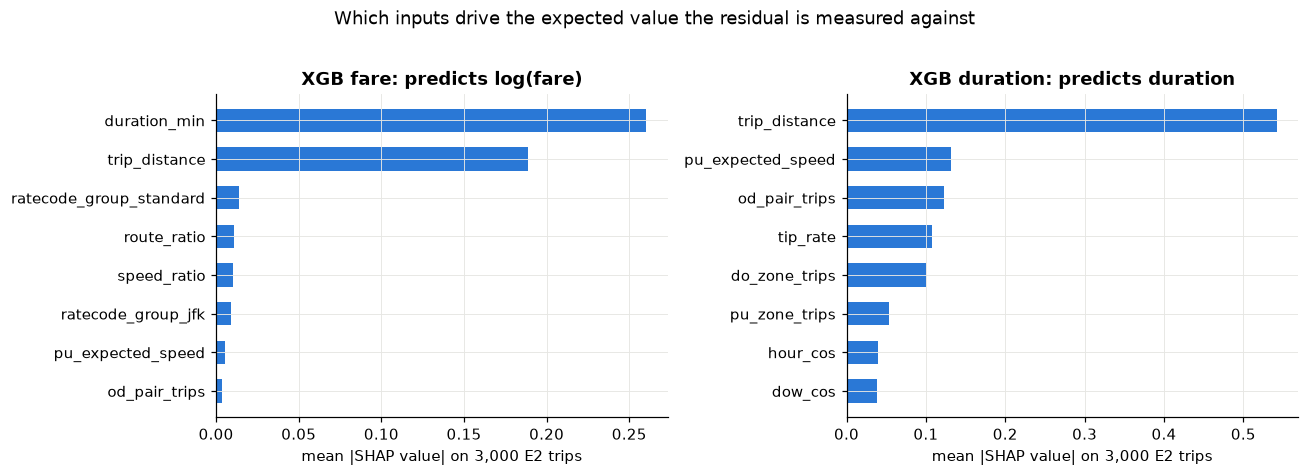

In [17]:
rng = np.random.default_rng(42)
sample = X2[rng.choice(len(X2), 3000, replace=False)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (title, model, cols) in zip(axes, [("XGB fare: predicts log(fare)", xgb_fare, XGB_FARE_COLS),
                                           ("XGB duration: predicts duration", xgb_duration, DURATION_COLS)]):
    values = shap.TreeExplainer(model).shap_values(sample[:, cols])
    imp = pd.Series(np.abs(values).mean(axis=0), index=[MODEL_COLUMNS[c] for c in cols]).nlargest(8)[::-1]
    ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
    ax.set_title(title)
    ax.set_xlabel("mean |SHAP value| on 3,000 E2 trips")
fig.suptitle("Which inputs drive the expected value the residual is measured against", y=1.02)
plt.tight_layout()
plt.show()

XGBoost fare bases its prediction almost entirely on duration and distance, followed with much smaller contributions by rate code, route ratio and speed ratio. This matches the tariff itself: the fare is computed from distance and slow time. No column derived from the fare appears in the list, so the score does not predict the fare from itself.

Findings: XGBoost fare sees four types and is the strongest model on small fare errors (lift 95 for a $5 inflation in Section 4). 27.8% of its flags are negotiated-fare (code 5) trips, although in Task 1 I saw that this rate is used on a very small share of trips. Because the fare does not depend on distance under a negotiated rate, the model systematically sees these trips as "mispriced". Some of them really are erroneous (Section 6), but this is a segment effect.

### 3.7 XGBoost duration

How it works: The same idea for duration: the model predicts the trip's duration from distance, time, zone and the zone's expected speed. The score is |actual duration − prediction|. Speed ratio and fare excess, which contain the duration directly, were removed from the inputs.

Parameters: The chosen setting is depth 4, `min_child_weight` 200 and pseudo-Huber loss. Pseudo-Huber grows linearly instead of quadratically for large errors, which limits how far extreme values pull the model. This mattered so that the 24-hour records already present in training would not distort the model.

Findings: In the SHAP plot above, the duration prediction rests first on distance, then on the zone's expected speed and the volume of the pickup–dropoff pair. The model is completely blind to fare errors (lift 0.1 at $25) because the fare is not among its inputs. It is very strong on duration errors (lift 99.3 and 99.5). I checked two issues separately: training stopping at the 4,000-tree cap, and the presence of `tip_rate`, which is derived from the fare, among the inputs.

In [18]:
kh5 = pd.read_csv(K28_DIR / "kh5_xgb_duration_checks.csv")
kh5["model"] = kh5["model"].str.replace("K28", "saved model")
kh5["best_iteration"] = kh5["best_iteration"].str.replace(" (K28 log)", "")
kh5 = kh5.rename(columns={"top-1% overlap with K28 on E": "top-1% overlap with saved model on E"})
kh5[["model", "best_iteration", "top-1% overlap with saved model on E", "mean lift fine", "mean lift coarse",
     "congestion probe (+30 min, +$15)", "DST recall %"]].set_index("model")

,best_iteration,top-1% overlap with saved model on E,mean lift fine,mean lift coarse,"congestion probe (+30 min, +$15)",DST recall %
model,,,,,,
"saved model (lr 0.1, cap 4000)",3997-3999,100.00,36.60,48.74,87.40,99.90
"lr 0.3, cap 4000",3999,84.30,36.17,49.04,85.50,99.23
"no tip_rate (lr 0.1, cap 4000)",3999,71.50,33.96,49.54,83.40,99.74


With a learning rate three times higher the model still stopped at the cap, but its flagged top 1% overlapped 84.3% with the saved model and the small- and large-error lift barely changed (36.2 vs 36.6). The incomplete convergence does not affect the results; the validation loss keeps improving in very small steps. Removing `tip_rate` dropped the overlap to 71.5%, but detection power stayed the same (34.0 vs 36.6) and the congestion control test fell from 87.4 to 83.4. `tip_rate` changes the score but does not behave like a leak.

The real problem of XGBoost duration is traffic: 67% of its flags come from the slowest traffic decile and it flags the congestion control test with 87.4 points. The model says "this duration is long for this distance", but it cannot tell whether the long duration comes from legitimate congestion.

### 3.8 Autoencoder

How it works: The autoencoder compresses the 74 columns first to 48 and then to 16 neurons, and expands them back to 74 columns. The network only learns to reproduce its input. The 16-neuron bottleneck prevents it from memorising each trip; the model has to learn the typical relations between columns (how distance, duration and fare change together). A trip that does not follow these relations gets a large reconstruction error.

Parameters: Loss is mean squared error, optimizer Adam. Training stops when the validation loss has not improved by more than 0.1% for 8 epochs. I computed the score only from the reconstruction error of the six measurement columns. When the error of all columns was used, noise in the binary columns dominated the score (in Appendix C the small-error lift of the 74-column score is 8.2, that of the chosen score 61.0). I kept the context columns in the input, however: an autoencoder without context could not know which trip is normal in which zone.

To reduce sensitivity to the seed, I also used the average score of three autoencoders trained with the same settings and three different seeds (AE 3-seed ensemble).

To see why the autoencoder flags a trip, I looked at how the error is distributed over the six measurement columns in flagged trips.

In [19]:
err = ((ae_members[0](torch.from_numpy(X2)) - torch.from_numpy(X2)) ** 2).detach().numpy()[:, MEASUREMENT_MASK]
ae_flag = live_e2["AE"] > np.quantile(saved_calib["AE"], 0.99)
share = err[ae_flag] / err[ae_flag].sum(axis=1, keepdims=True)
meas_names = np.array(MODEL_COLUMNS)[MEASUREMENT_MASK]
pd.DataFrame({"mean share of the error %": 100 * share.mean(axis=0),
              "largest share in % of flagged trips": 100 * pd.Series(share.argmax(axis=1)).value_counts(normalize=True).reindex(range(6), fill_value=0).to_numpy()},
             index=meas_names).sort_values("mean share of the error %", ascending=False).round(1)

,mean share of the error %,largest share in % of flagged trips
trip_distance,39.00,58.60
duration_min,23.00,16.40
fare_excess,22.80,15.50
speed_ratio,14.00,9.30
route_ratio,1.00,0.20
tip_rate,0.10,0.00


In flagged trips, on average 39% of the error comes from distance, and distance has the largest share in 58.6% of the trips. Duration (23.0%) and fare excess (22.8%) follow. Route ratio and tip rate contribute almost nothing. In practice the autoencoder asks "are distance, duration and fare consistent with each other". This table also predicts that it cannot see tip errors; I confirmed this with injection in Section 5.1.

Findings: The autoencoder sees four types, is stronger than XGBoost fare on duration errors and almost never flags the 30-minute congestion control test (2.9); in 4.2 I show that this is a tolerance difference. 60.3% of its flags are also caught by the Task 2 rules, which shows that the autoencoder is very sensitive to large data errors.

### 3.9 Effect of the contamination parameter

The contamination parameter directly affects the output. I tested this on Isolation Forest and LOF with four values.

In [20]:
pd.read_csv(K28_DIR / "kr4a_contamination_invariance.csv").set_index("contamination").round(3)

,IF max|d score| vs auto,IF offset_,IF predict-anomaly %,LOF max|d score| vs auto,LOF offset_,LOF predict-anomaly %
contamination,,,,,,
auto,0.00,-0.50,10.79,0.00,-1.50,0.28
0.005,0.00,-0.55,0.65,0.00,-1.43,0.51
0.01,0.00,-0.54,1.41,0.00,-1.36,1.06
0.05,0.00,-0.51,6.67,0.00,-1.20,5.76


The scores are identical for all four values (difference 0.0). The only thing that changes is `offset_`, the threshold used by the `predict` method; the flagged share comes out roughly equal to the contamination value. Contamination does not change what the model learns, only how many alarms are produced. There is also a trap: with `contamination="auto"`, Isolation Forest uses a fixed threshold (−0.5) and flags 10.8% of the data. Using the default is itself a large alarm-budget decision.

So I treated contamination as a budget in every model and took the threshold from a percentile of the calibration set. The real question is which model still works when the budget gets narrower.

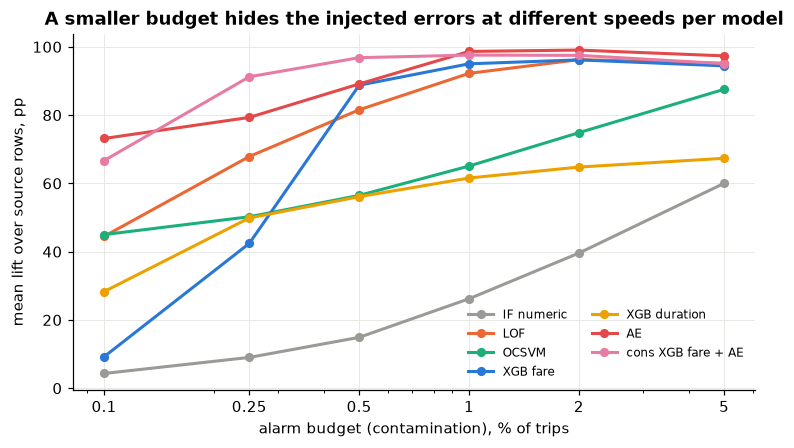

In [21]:
kk1 = pd.read_csv(K28_DIR / "kk1_budget_injection.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
palette = dict(zip(MODELS6 + ["cons XGB fare + AE"], [GREY, ORANGE, AQUA, BLUE, YELLOW, RED, MAGENTA]))
for name, g in kk1.groupby("source", sort=False):
    ax.plot(g["budget %"], g["mean lift (4 measurement types)"], marker="o", ms=5, lw=2, color=palette[name], label=name)
ax.set_xscale("log")
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 5], ["0.1", "0.25", "0.5", "1", "2", "5"])
ax.set_xlabel("alarm budget (contamination), % of trips")
ax.set_ylabel("mean lift over source rows, pp")
ax.set_title("A smaller budget hides the injected errors at different speeds per model")
ax.legend(ncol=2, fontsize=8, frameon=False)
plt.show()

When the budget drops from 1% to 0.1%, the models lose ground at very different rates. The autoencoder stays strong at the narrow budget too (mean lift 98.7 at 1%, 73.2 at 0.1%). XGBoost fare drops from 95.0 at 1% to 9.2 at 0.1%. The reason is visible in Section 6: the very top of the XGBoost fare ranking is full of real large errors with negotiated or zero fares. At a narrow budget these trips fill the queue and leave no room for the injected medium-sized errors. This finding is the basis of the "rules-first" recommendation in Section 8: large errors that a rule can catch should be removed from the model's queue first.

### 3.10 Hyperparameter sensitivity

Weeks of grid search are not needed here; a reasonable range is enough. For each model I tried the parameter that affects the result most at a few values and measured the results on E2.

In [22]:
kh1 = pd.read_csv(K28_DIR / "kh1_hyperparameter_sensitivity.csv")
kh1_small_k = pd.read_csv(K28_DIR / "kh1b_lof_small_k.csv")
first_lof = kh1.index[kh1["family"] == "LOF"][0]
kh1 = pd.concat([kh1.iloc[:first_lof], kh1_small_k, kh1.iloc[first_lof:]], ignore_index=True)
kh1[["model", "stab_top1_AB", "mean lift fine", "mean lift coarse", "congestion probe (+30 min, +$15)", "DST recall %", "fit_s"]].set_index("model").round(1)


,stab_top1_AB,mean lift fine,mean lift coarse,"congestion probe (+30 min, +$15)",DST recall %,fit_s
model,,,,,,
IF n_est=100 max_samples=256,59.00,4.10,10.10,25.70,18.60,1
IF n_est=100 max_samples=2048,59.20,4.70,15.90,39.80,18.80,2
IF n_est=100 max_samples=8192,68.30,6.80,28.40,62.60,33.00,3
IF n_est=1500 max_samples=256,87.70,4.30,14.10,55.70,16.70,13
IF n_est=1500 max_samples=2048,89.20,6.20,24.30,66.60,25.60,28
IF n_est=1500 max_samples=8192,90.40,7.30,30.10,64.40,34.70,37
LOF k=5,41.70,40.20,84.10,16.40,97.50,90
LOF k=10,59.30,39.80,89.20,22.00,99.00,81
LOF k=20,68.70,36.40,91.10,26.90,99.00,22


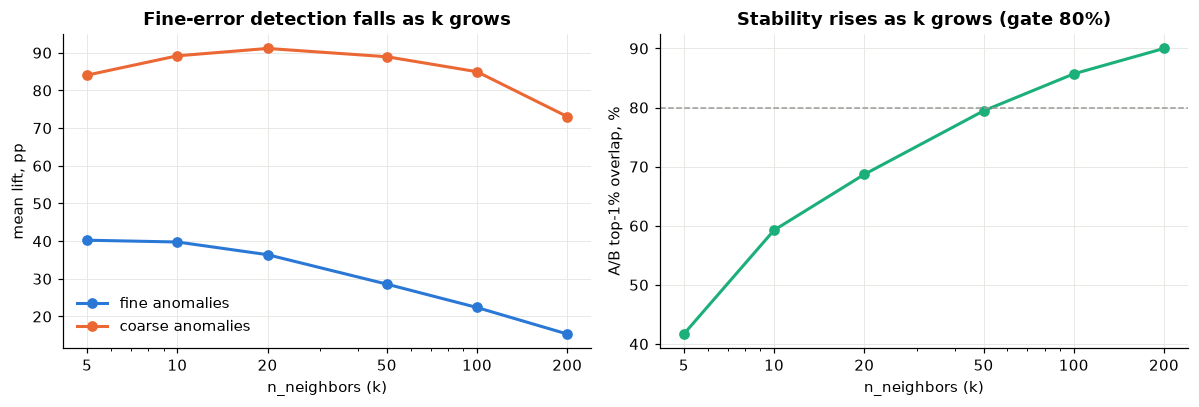

In [23]:
lof_k = kh1[kh1["family"] == "LOF"].assign(k=lambda d: d["setting"].astype(int))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(lof_k["k"], lof_k["mean lift fine"], marker="o", lw=2, color=BLUE, label="fine anomalies")
axes[0].plot(lof_k["k"], lof_k["mean lift coarse"], marker="o", lw=2, color=ORANGE, label="coarse anomalies")
axes[0].set_xlabel("n_neighbors (k)")
axes[0].set_ylabel("mean lift, pp")
axes[0].set_title("Fine-error detection falls as k grows")
axes[0].legend(frameon=False)
axes[1].plot(lof_k["k"], lof_k["stab_top1_AB"], marker="o", lw=2, color=AQUA)
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(lof_k["k"], lof_k["k"].astype(str))
axes[1].axhline(80, color=GREY, ls="--", lw=1)
axes[1].set_xlabel("n_neighbors (k)")
axes[1].set_ylabel("A/B top-1% overlap, %")
axes[1].set_title("Stability rises as k grows (gate 80%)")
plt.tight_layout()
plt.show()

In Isolation Forest, both detection and stability rise with the number of trees and `max_samples`, but even the best setting reaches only 7.3 small-error lift; Isolation Forest is weak in every setting. XGBoost fare is insensitive to depth: small-error lift is 90.0–91.7 at depths 4, 6 and 8. The kNN distance is weaker than LOF. Every row in this table is a separate retraining; although the depth-6 row uses the same setting as the saved model, its congestion control test and daylight saving time results differ from the saved model by a few points (62.3 vs 65.5; 72.1 vs 68.1). This is the size of the variability of a single retraining.

In LOF, k is a trade-off. As k gets smaller the model looks more locally and catches more errors, but stability falls quickly: at k = 20 the small-error lift is 36.4 and stability 68.7, at k = 5 they are 40.2 and 41.7. Small-error lift saturates around 40 below k = 10. As k grows, stability rises and detection falls. I chose k = 100 because it is the smallest value that comfortably passes the stability gate. At no value of k did LOF come close to the small-error lift of the autoencoder (63.6) or of XGBoost fare (91.7). No variant in the table beats the selected models on the small- and large-error axes together.

### 3.11 Open-source models from the literature (PyOD)

As extra work I tried five methods from the PyOD library (Zhao et al., 2019) with default settings under the same protocol: ECOD, COPOD, HBOS, LODA and DeepSVDD. I ran each with the 74 columns and with the 19 numeric columns separately. Before seeing the results I wrote a hypothesis: the methods that treat the columns as independent (ECOD, COPOD, HBOS) and LODA, which uses random projections, cannot see a conditional anomaly of the "this fare for this distance" kind.

In [24]:
km = pd.read_csv(K28_DIR / "km_literature_models.csv")
km[["model", "stab_top1_AB", "mean lift fine", "mean lift coarse", "DST recall %", "rubric real % (E2)"]].set_index("model").round(1)

,stab_top1_AB,mean lift fine,mean lift coarse,DST recall %,rubric real % (E2)
model,,,,,
ECOD all74,99.60,1.90,2.80,2.10,21.70
ECOD numeric19,99.10,6.90,13.30,6.10,6.70
COPOD all74,90.10,0.70,2.90,2.10,28.00
COPOD numeric19,72.90,3.90,16.00,9.30,7.60
HBOS all74,93.40,-0.00,0.00,2.60,29.00
HBOS numeric19,75.70,2.50,5.30,23.70,4.50
LODA all74,10.10,1.80,5.20,13.80,6.20
LODA numeric19,43.40,2.80,15.50,12.20,8.90
DeepSVDD all74,82.60,0.10,0.10,9.50,30.80


The hypothesis held. None of the five methods produced more than 6.9 points of lift on the small-error injections; XGBoost fare reached 91.7 and the autoencoder 63.6. The 74-column ECOD is the most stable method (99.6%), but its small-error lift is 1.9. This is the clearest example that stability alone cannot be a selection criterion. The 74-column DeepSVDD does not see the large errors either (0.1); I read this as a training run that collapsed in this setting.

I used these methods as a negative control: they show that seeing conditional anomalies requires a method that models the relations between columns.

### 3.12 Consensus

I also tested whether combining models gives a better score. I converted each model's score to its percentile rank on the calibration set and averaged the ranks. I built three candidates: all six models, XGBoost fare + autoencoder, and those two plus XGBoost duration.

In [25]:
cons = pd.read_csv(K28_DIR / "kg4_consensus_decision.csv").rename(columns={"index": "candidate"}).set_index("candidate")
kr1 = pd.read_csv(K28_DIR / "kr1_stability_with_consensus.csv").groupby("model")["top1"].min()
cons["A/B top-1% overlap (worst of 3)"] = kr1.rename({"cons XGB fare + AE": "cons XGB fare + AE"})
cons.drop(columns="passes").round(1)

,mean lift (anomaly variants),congestion probe lift,A/B top-1% overlap (worst of 3)
candidate,,,
IF numeric,19.30,66.50,90.00
LOF,68.00,37.00,85.70
OCSVM,45.80,49.50,82.70
XGB fare,93.90,65.50,85.00
XGB duration,50.20,90.70,85.60
AE,85.30,2.90,80.40
cons all 6,70.00,98.40,NaN
cons XGB fare + AE,94.60,47.90,77.10
cons XGB fare + AE + XGB dur,73.10,96.00,NaN


The average of all six models is weaker than XGBoost fare on the injections (70.0 vs 93.9) and flags the congestion control test with 98.4 points. A rank average counts weak models as much as strong ones and pushes forward the only thing they share, slow traffic. XGBoost fare + autoencoder equals the best single model on the injections (94.6 vs 93.9) and is better than XGBoost fare on the congestion control test (47.9 vs 65.5). But its worst-pair A/B stability stayed at 77.1 and did not pass the 80% gate I had set beforehand. The noise of two weakly correlated models adds up in the average. I therefore used the consensus only as a reference score in the Task 3 comparison.

## 4. Comparing the models with each other

### 4.1 Do they flag the same records

First I looked at how similar the scores are. Spearman correlation compares the whole ranking; Jaccard measures only how much the sets flagged at the 1% threshold overlap.

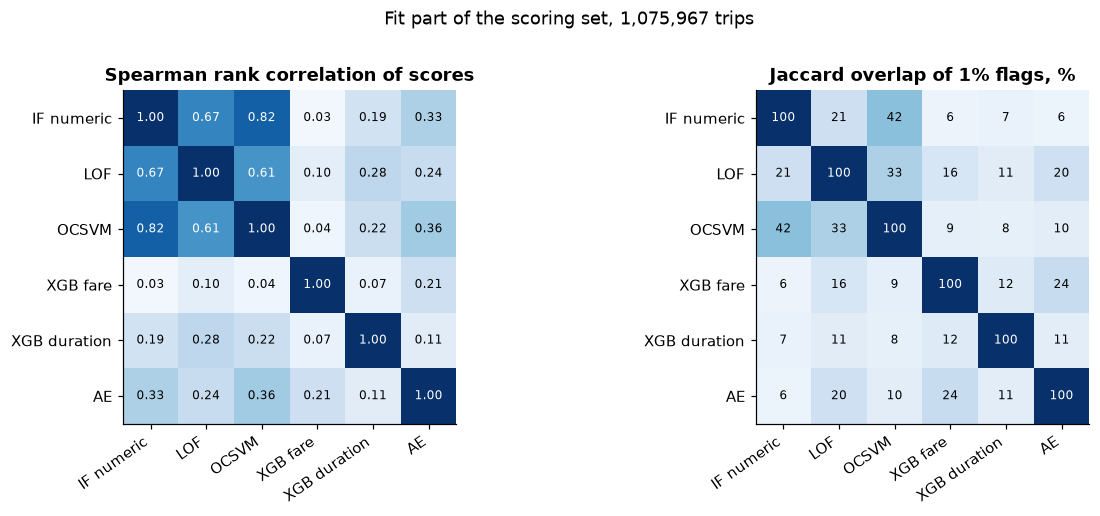

In [26]:
fit = scoring[scoring["in_fit_window"]].reset_index(drop=True)
score_cols = [f"score_{m}" for m in MODELS6]
rho = fit[score_cols].rank().corr().values
flags = fit[[f"flag_{m}" for m in MODELS6]].to_numpy()
inter = flags.T.astype(int) @ flags.astype(int)
jaccard = 100 * inter / (flags.sum(0)[:, None] + flags.sum(0)[None, :] - inter)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, mat, title, fmt in [(axes[0], rho, "Spearman rank correlation of scores", "{:.2f}"),
                            (axes[1], jaccard, "Jaccard overlap of 1% flags, %", "{:.0f}")]:
    ax.imshow(mat, cmap="Blues", vmin=0, vmax=mat.max() if mat.max() > 1 else 1)
    ax.set_xticks(range(6), MODELS6, rotation=35, ha="right")
    ax.set_yticks(range(6), MODELS6)
    ax.grid(False)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if mat[i, j] > 0.6 * mat.max() else "black")
    ax.set_title(title)
fig.suptitle(f"Fit part of the scoring set, {len(fit):,} trips", y=1.01)
plt.tight_layout()
plt.show()

The models split into two families. Isolation Forest, LOF and OCSVM resemble each other (Spearman 0.61–0.82); Isolation Forest and OCSVM carry almost the same signal (0.82) and 42% of their flagged sets overlap. XGBoost fare, XGBoost duration and the autoencoder are very different both from each other and from the first family: XGBoost fare correlates 0.03–0.10 with the geometry models and 0.21 with the autoencoder. The residual and reconstruction models do not ask the same question: one looks at the fare, one at the duration, one at the joint consistency of the measurements.

### 4.2 Which model catches which type of anomaly

To answer this question, I scored all 14 injection variants live with every model and collected the lift in a heatmap. The last row is the lift of the Task 3 union flag on the same rows.

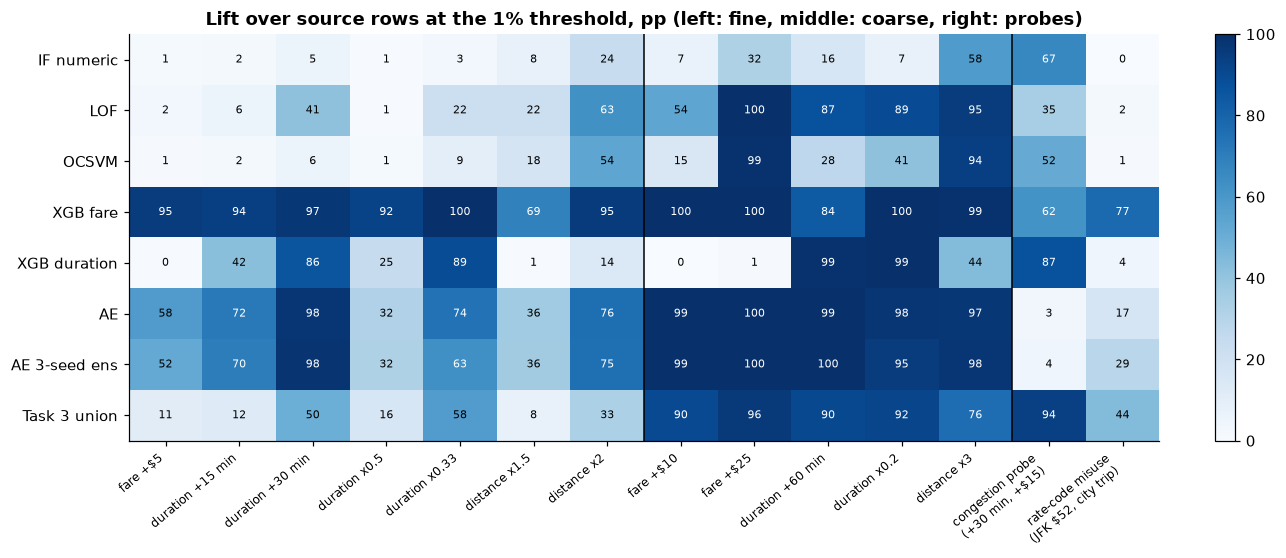

In [27]:
def lift_table(scorers, budget_q=0.99):
    rows = {}
    for name, f in scorers.items():
        calib = saved_calib[name] if name in saved_calib else saved_calib["AE"]
        thr = np.quantile(calib, budget_q) if name in saved_calib else thresholds["p99"]["AE 3-seed ens"]
        base = live_e2[name]
        rows[name] = {v: 100 * ((f(Xi, yi) > thr).mean() - (base[src] > thr).mean()) for v, (src, Xi, yi) in inj_e2.items()}
    return pd.DataFrame(rows).T

lift_e2 = lift_table({n: SCORERS[n] for n in MODELS6 + ["AE 3-seed ens"]})
lift_e2.loc["Task 3 union"] = km.set_index("model").loc["T3 union (reference)", list(inj_e2)]
order = FINE + COARSE + PROBES
fig, ax = plt.subplots(figsize=(13, 4.8))
im = ax.imshow(lift_e2[order].values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(order)), [v.replace(" (", "\n(") for v in order], rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(lift_e2)), lift_e2.index)
ax.grid(False)
for i in range(len(lift_e2)):
    for j, v in enumerate(order):
        val = lift_e2.iloc[i][v]
        ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=7.5, color="white" if val > 60 else "black")
ax.axvline(len(FINE) - 0.5, color="black", lw=1)
ax.axvline(len(FINE) + len(COARSE) - 0.5, color="black", lw=1)
ax.set_title("Lift over source rows at the 1% threshold, pp (left: fine, middle: coarse, right: probes)")
fig.colorbar(im, ax=ax, fraction=0.02)
plt.show()

The heatmap shows the specialities of the models clearly:

- XGBoost fare is the strongest model on almost all small errors (69–100). It catches rate-code misuse best (77) because its prediction uses the rate code.
- XGBoost duration sees only duration errors and the large distance error; its lift is 0–1 on fare errors and 1–14 on small distance errors.
- The autoencoder and the ensemble catch all large errors (95–100) and fall behind XGBoost on small errors (32–98).
- Isolation Forest and OCSVM miss most small errors (lift 1–18 except distance ×2); LOF is strong on large errors and weak on small ones.
- On the congestion control test the ranking flips: the autoencoder and the ensemble almost never flag these legitimate trips (3–4), XGBoost duration 87, Task 3 94. Below I test how robust this is by changing the size of the test.

The answer to "which model is best" depends on which anomaly type matters.

#### Size of the congestion control test

The congestion control test was defined at a single size (30 minutes, $15). To see whether the autoencoder is really robust to traffic or only tolerates this particular size, I grew the test from 10 to 60 minutes. At each step the fare rose consistently with the tariff ($0.50 per minute), so every row is still legitimate congestion.

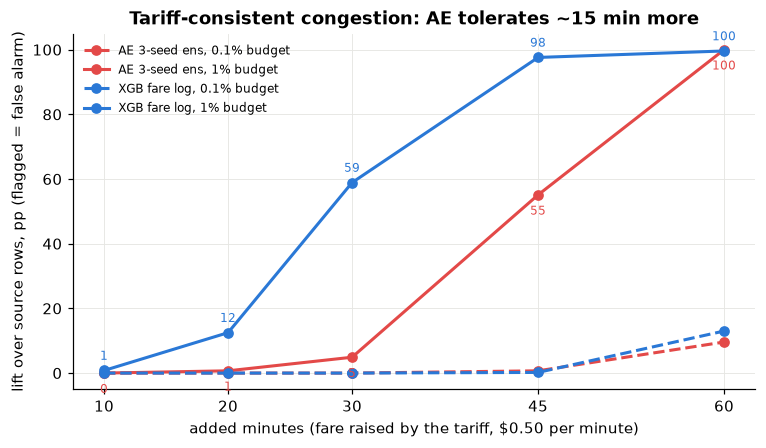

In [28]:
sweep = pd.read_csv(K28_DIR / "kp1_congestion_sweep.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
for (score, budget), g in sweep.groupby(["score", "budget"], sort=False):
    color = RED if score.startswith("AE") else BLUE
    ls = "-" if budget == "1%" else "--"
    ax.plot(g["added minutes"], g["lift pp"], marker="o", lw=2, ls=ls, color=color, label=f"{score}, {budget} budget")
    if budget == "1%":
        for x, v in zip(g["added minutes"], g["lift pp"]):
            ax.annotate(f"{v:.0f}", (x, v), textcoords="offset points", xytext=(0, 7 if color == BLUE else -13), ha="center", fontsize=8, color=color)
ax.set_xticks(sorted(sweep["added minutes"].unique()))
ax.set_xlabel("added minutes (fare raised by the tariff, $0.50 per minute)")
ax.set_ylabel("lift over source rows, pp (flagged = false alarm)")
ax.set_title("Tariff-consistent congestion: AE tolerates ~15 min more")
ax.legend(frameon=False, fontsize=8)
plt.show()


XGBoost fare log starts flagging at 20 minutes (12.5 at 1%; 58.9 at 30 minutes). The autoencoder ensemble is still at 4.9 at 30 minutes, but rises to 55.1 at 45 minutes and 100 at 60 minutes. So the autoencoder is not blind to traffic; it tolerates a consistent delay about 15 minutes longer. The other side of this trade-off is that both models catch the 60-minute cases where the meter was left running. The "models produce fewer false congestion alarms" result in Section 5 holds within this tolerance range.

### 4.3 Trips that several models agree on

I checked whether the number of models flagging a trip indicates how likely it is to be a real anomaly.

In [29]:
slow_cut = fit["speed_ratio"].quantile(0.10)
t3_stat_cols = [c for c in fit.columns if c.startswith("t3_") and c != "t3_rule"]
n_models = flags.sum(axis=1)
depth = pd.DataFrame({"models agreeing": n_models, "T3 statistical": fit[t3_stat_cols].fillna(False).any(axis=1),
                      "rule": fit["t3_rule"], "slow decile": fit["speed_ratio"] <= slow_cut})
depth["models agreeing"] = depth["models agreeing"].clip(upper=4).map(lambda k: f"{k}+" if k == 4 else str(k))
agree = depth.groupby("models agreeing").agg(trips=("rule", "size"), **{c + " %": (c, "mean") for c in ["T3 statistical", "rule", "slow decile"]})
agree[["T3 statistical %", "rule %", "slow decile %"]] *= 100
agree.insert(1, "share of trips %", 100 * agree["trips"] / len(depth))
agree.round(2)

,trips,share of trips %,T3 statistical %,rule %,slow decile %
models agreeing,,,,,
0,1037142,96.39,2.59,0.93,9.00
1,23920,2.22,34.06,18.81,31.88
2,8032,0.75,39.21,37.14,20.88
3,4249,0.39,46.51,36.46,25.11
4+,2624,0.24,81.33,31.67,56.55


Trips on which four or more models agree are 0.24% of the training period. 56.6% of them fall in the slowest traffic decile (9.0% among trips no model flags). Because all three geometry models flag slow trips, the "how many models flagged it" count mostly counts traffic. I therefore did not use the agreement count as a priority signal.

### 4.4 Threshold-free comparison

The results so far depend on a threshold. To measure ranking quality independently of the threshold, I computed average precision (AP) on E3: when each family's injected rows are mixed into the non-rule trips of E3, how high does the model rank them. The AP of a random ranking equals the share of injected rows, about 1%.

In [30]:
ap = pd.read_csv(K28_DIR / "kz4_average_precision_e3.csv").set_index("model")
ap[["AP fine mean", "AP coarse mean", "rate-code misuse (JFK $52, city trip)"]].round(1)

,AP fine mean,AP coarse mean,"rate-code misuse (JFK $52, city trip)"
model,,,
XGB fare log,61.80,76.70,52.80
XGB fare $|resid|,42.70,59.40,62.70
AE single,57.00,91.60,18.70
AE 3-seed ens,54.20,90.30,37.20


On the small- and large-error averages the AP of every score is 40–90 times that of a random ranking. But the best model again depends on the anomaly type: XGBoost fare log on small errors (61.8), the single autoencoder on large errors (91.6), and the dollar residual on rate-code misuse (62.7). The picture from the thresholded results does not change under the threshold-free measure: on this data no single model is best on every type.

## 5. Comparison with the statistical methods

### 5.1 Where we won, where we lost

To score the injected rows, I re-implemented the Task 3 flags in Python. First I checked that the re-implementation gives the same result as the Task 3 SQL flags.

In [31]:
port = pd.read_csv(K28_DIR / "kg3_t3_port_agreement.csv").rename(columns={"index": "Task 3 flag", "agree_pct": "row agreement with SQL %"})
port.set_index("Task 3 flag").T

Task 3 flag,distance,duration,speed_ratio,fare_excess,tip,rare_od_pair,physical,economic
row agreement with SQL %,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00


Row-level agreement is 100% for all eight flags. In the comparison I used the union of all Task 3 statistical flags (univariate MAD flags and segment-wise robust Mahalanobis). This union flags about 4% of the trips, four times the models' 1% budget, so the comparison was made with a budget difference in Task 3's favour.

The plot below is the E3 result. I opened E3 only once, and before seeing the result I wrote this hypothesis: the consensus score catches more than the Task 3 union on at least six of the seven small-error variants, with the lower confidence bound above zero.

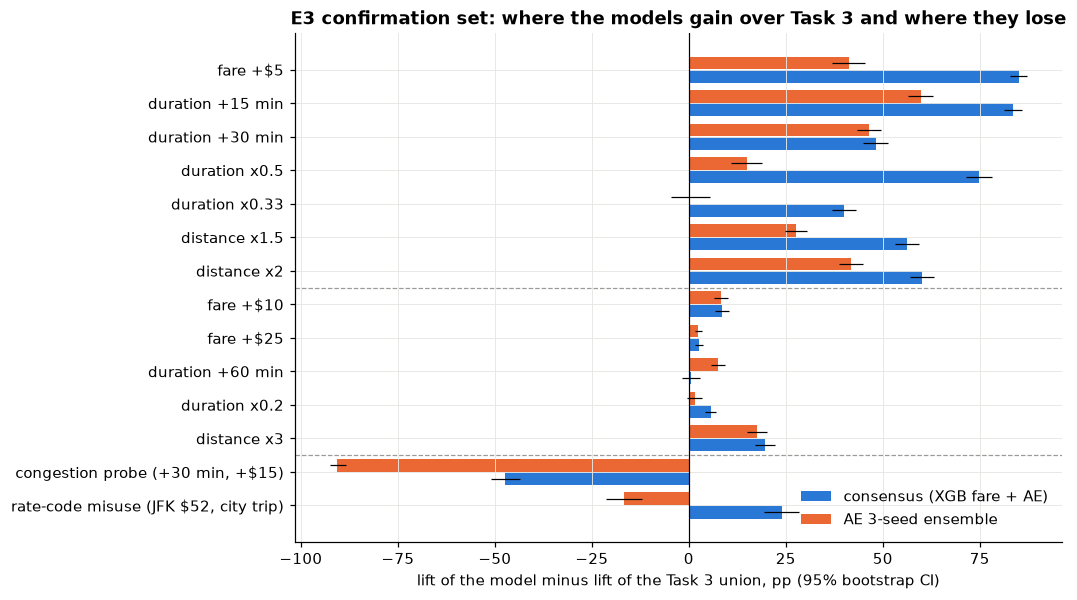

In [32]:
gains = pd.read_csv(K28_DIR / "e3" / "kw1_t3_gains.csv").set_index("variant")
ci = gains["consensus p99 CI"].str.split(r"\.\.", expand=True).astype(float)
ci_ae = gains["AE 3-seed ens p99 CI"].str.split(r"\.\.", expand=True).astype(float)
plot_order = FINE + COARSE + PROBES
y = np.arange(len(plot_order))
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(y + 0.2, gains.loc[plot_order, "consensus p99 - T3"], height=0.38, color=BLUE, label="consensus (XGB fare + AE)")
ax.errorbar(gains.loc[plot_order, "consensus p99 - T3"], y + 0.2,
            xerr=[gains.loc[plot_order, "consensus p99 - T3"] - ci.loc[plot_order, 0], ci.loc[plot_order, 1] - gains.loc[plot_order, "consensus p99 - T3"]],
            fmt="none", ecolor="black", lw=0.8)
ax.barh(y - 0.2, gains.loc[plot_order, "AE 3-seed ens p99 - T3"], height=0.38, color=ORANGE, label="AE 3-seed ensemble")
ax.errorbar(gains.loc[plot_order, "AE 3-seed ens p99 - T3"], y - 0.2,
            xerr=[gains.loc[plot_order, "AE 3-seed ens p99 - T3"] - ci_ae.loc[plot_order, 0], ci_ae.loc[plot_order, 1] - gains.loc[plot_order, "AE 3-seed ens p99 - T3"]],
            fmt="none", ecolor="black", lw=0.8)
ax.set_yticks(y, plot_order)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.axhline(len(FINE) - 0.5, color=GREY, lw=0.8, ls="--")
ax.axhline(len(FINE) + len(COARSE) - 0.5, color=GREY, lw=0.8, ls="--")
ax.set_xlabel("lift of the model minus lift of the Task 3 union, pp (95% bootstrap CI)")
ax.set_title("E3 confirmation set: where the models gain over Task 3 and where they lose")
ax.legend(frameon=False, loc="lower right")
plt.show()

The hypothesis held on all seven small-error variants; the mean gain of the consensus is 64.0 points. The largest gains are on errors too small for the univariate bounds of Task 3: $5 fare inflation +85.0, 15-minute duration addition +83.6, halved duration +74.9, distance ×1.5 +56.2. On large errors the two approaches are equal; for the 60-minute addition the difference is +0.6 points and the confidence interval contains zero. Task 3 already caught these errors.

The consensus is not the model I recommend, because it did not pass the stability gate (3.12); I use it here to show the upper bound. The autoencoder ensemble I recommend is ahead of Task 3 on its own in at least six of the seven small-error variants, with a mean gain of +33.2 points (orange bars in the plot).

In two places the models lose or their gain is debatable. On the congestion control test the models flag less (consensus −47.4, autoencoder ensemble −90.6); since this test is a legitimate trip, flagging less is the correct behaviour here and shows a Task 3 false alarm. On rate-code misuse the consensus gains +24.0 while the autoencoder ensemble is behind Task 3 (−16.8): the autoencoder score does not look at the rate-code column.

Because the injection families are close to what the models are designed for (2.3), I made a second comparison with families the models never saw. The upper part of the table below shows the E3 families; rate-code misuse is the only one of them never used in model selection. The lower part shows the new families I added after model selection was finished. For the new families the "model" column is the best of three scores (XGBoost fare log, XGBoost fare $|resid|, autoencoder ensemble); picking the best after the fact makes the comparison optimistic for the models. The models work at the 1% queue, Task 3 at its own 4% budget. When both sides stay below 20 points I called the result "both weak".

In [33]:
kt1 = pd.read_csv(K28_DIR / "kt1_new_injection_families.csv").set_index("family")
inside = pd.DataFrame({"T3 union": gains["T3 union lift"], "model": gains["T3 union lift"] + gains["consensus p99 - T3"]})
inside["model score"] = "consensus (XGB fare + AE)"
inside["set"] = np.where(inside.index.isin(PROBES[1:]), "E3, family held out of selection", "E3, family used in selection")
new_cols = {"XGB fare log @1%": "XGB fare log", "XGB fare $|resid| @1%": "XGB fare $|resid|", "AE 3-seed ens @1%": "AE 3-seed ens"}
outside = pd.DataFrame({"T3 union": kt1["T3 union"], "model": kt1[list(new_cols)].max(axis=1),
                        "model score": "best of 3: " + kt1[list(new_cols)].idxmax(axis=1).map(new_cols)})
outside["set"] = "E2, new family (added after selection)"
won_lost = pd.concat([inside, outside])
won_lost["gain"] = won_lost["model"] - won_lost["T3 union"]
won_lost["verdict"] = np.select(
    [won_lost.index == PROBES[0], (won_lost["model"] < 20) & (won_lost["T3 union"] < 20), won_lost["gain"] > 5, won_lost["gain"] < -5],
    ["model flags less (correct: legitimate trip)", "both weak (< 20)", "model gains", "model loses"], "equal (within 5 pp)")
won_lost[["T3 union", "model", "gain", "model score", "set", "verdict"]].round(1)


,T3 union,model,gain,model score,set,verdict
fare +$5,11.00,96.00,85.00,consensus (XGB fare + AE),"E3, family used in selection",model gains
fare +$10,91.20,99.70,8.50,consensus (XGB fare + AE),"E3, family used in selection",model gains
fare +$25,97.10,99.70,2.60,consensus (XGB fare + AE),"E3, family used in selection",equal (within 5 pp)
duration +15 min,13.00,96.60,83.60,consensus (XGB fare + AE),"E3, family used in selection",model gains
duration +30 min,50.50,98.70,48.20,consensus (XGB fare + AE),"E3, family used in selection",model gains
duration +60 min,91.70,92.30,0.60,consensus (XGB fare + AE),"E3, family used in selection",equal (within 5 pp)
duration x0.5,16.00,90.90,74.90,consensus (XGB fare + AE),"E3, family used in selection",model gains
duration x0.33,59.10,99.10,40.00,consensus (XGB fare + AE),"E3, family used in selection",model gains
duration x0.2,94.00,99.60,5.60,consensus (XGB fare + AE),"E3, family used in selection",model gains
distance x1.5,8.20,64.40,56.20,consensus (XGB fare + AE),"E3, family used in selection",model gains


On the new families the table is more balanced:

- The models clearly win on undercharging: the models caught a $5 fare reduction 98.7% of the time, while Task 3 did not see it at all (−1.0); for a halved fare it is 99.7 vs 15.7.
- The models clearly lose on tips: Task 3's tip flag caught a card tip multiplied by five 68.4% of the time, the best model 2.6%. XGBoost fare does not use the tip rate as an input, and, as shown in 3.8, the autoencoder error is fed almost nothing by the tip column.
- What nobody sees: a tariff-consistent long detour (best model 11.7 at ×1.3, Task 3 1.2; the model reaches 31.6 at ×1.5 but is still weak) and a phantom toll (7.6 vs 0). These are consistent within the trip, so they cannot be caught without knowing the real route. The matrix has no GPS coordinates.
- A meter left running (60 minutes and $30 extra) is caught on both sides.

The models do not replace Task 3, they complement it. A univariate rule such as the tip flag catches an error the models cannot see.

### 5.2 A known real error: the daylight saving time transition

As evidence independent of the injections, I scored live with the models the 8,989 trips whose duration was recorded one hour too long on the nights the clocks go forward, and compared them with the saved Task 3 flags on the same trips.

In [34]:
ki_dst = pd.read_csv(K28_DIR / "ki_dst_known_error.csv").set_index("index")["all DST trips %"]
dst_rows = {name: 100 * (SCORERS[name](X_dst, y_dst) > np.quantile(saved_calib[name], 0.99)).mean() for name in MODELS6}
dst_rows["AE 3-seed ens"] = 100 * (SCORERS["AE 3-seed ens"](X_dst, y_dst) > thresholds["p99"]["AE 3-seed ens"]).mean()
dst = pd.DataFrame({"recall of the 8,989 DST trips %": pd.Series(dst_rows)})
for t3 in ["T3 duration", "T3 speed_ratio", "T3 physical", "T3 any statistical", "|z fare_excess|", "sum z^2 measurement"]:
    dst.loc[t3] = ki_dst[t3]
dst["source"] = ["model, scored here"] * 7 + ["Task 3 flags / z-score baselines (saved)"] * 6
dst.round(1)

,"recall of the 8,989 DST trips %",source
IF numeric,25.60,"model, scored here"
LOF,95.00,"model, scored here"
OCSVM,52.30,"model, scored here"
XGB fare,68.10,"model, scored here"
XGB duration,99.90,"model, scored here"
AE,99.90,"model, scored here"
AE 3-seed ens,99.50,"model, scored here"
T3 duration,59.10,Task 3 flags / z-score baselines (saved)
T3 speed_ratio,70.00,Task 3 flags / z-score baselines (saved)
T3 physical,78.40,Task 3 flags / z-score baselines (saved)


In [35]:
pd.read_csv(K28_DIR / "kl_dst_feature_ablation.csv").rename(columns={"index": "model", "drop": "change, pp"}).set_index("model").round(2)

,as is,is_dst_transition_day = 0,"change, pp"
model,,,
IF numeric,25.60,25.60,0.00
LOF,95.02,91.20,3.82
OCSVM,52.29,45.01,7.28
XGB fare,68.08,68.04,0.04
XGB duration,99.90,99.97,-0.07
AE,99.90,99.90,0.00
cons,84.51,84.47,0.04


XGBoost duration and the autoencoder caught 99.9% of these trips, LOF 95.0%. In Task 3 the single flag that sees this error best is the physical Mahalanobis pair (78.4%); the union of all statistical flags reaches 97.2%, but with a four times wider budget. Simple z-score baselines (1.6% and 4.8%) barely see this error. Isolation Forest (25.6%) and OCSVM (52.3%) are weak again.

This result confirms the synthetic "duration +60 minutes" result on real data, but it is not fully independent second evidence, because both are the same kind of error. The second table shows whether giving the `is_dst_transition_day` column to the models affects the result: when the column is set to zero, the detection rate of the autoencoder and XGBoost duration does not change (difference 0.0 and −0.07 points); LOF and OCSVM drop by 3.8 and 7.3 points. The models find these trips through the inconsistency between distance and duration.

### 5.3 Do the two approaches flag the same trips on real data

Beyond the injections, I looked at how much the trips flagged by the models and by Task 3 overlap on real data. I used the 1,075,967 trips in the training-period part of the scoring set.

In [36]:
t3_any = fit[t3_stat_cols].fillna(False).any(axis=1).to_numpy()
rule = fit["t3_rule"].to_numpy()
rows = []
for j, m in enumerate(MODELS6):
    f = flags[:, j]
    rows.append({"model": m, "flagged": int(f.sum()), "also Task 3 statistical %": 100 * t3_any[f].mean(),
                 "also Task 2 rule %": 100 * rule[f].mean(), "model only %": 100 * (~t3_any[f] & ~rule[f]).mean()})
overlap = pd.DataFrame(rows).set_index("model")
overlap.loc["Task 3 union, caught by any model %"] = [int(t3_any.sum()), np.nan, np.nan, 100 * flags.any(axis=1)[t3_any].mean()]
overlap["flagged"] = overlap["flagged"].astype(int)
overlap.round(1)

,flagged,also Task 3 statistical %,also Task 2 rule %,model only %
model,,,,
IF numeric,10488,51.70,10.80,47.70
LOF,10820,46.30,27.60,42.60
OCSVM,10454,47.40,15.90,50.40
XGB fare,10872,28.20,42.30,40.60
XGB duration,11178,54.80,16.30,35.30
AE,10714,51.70,60.60,26.10
"Task 3 union, caught by any model %",42282,NaN,NaN,36.40


The two approaches flag largely different trips. 26–50% of each model's flags are in neither the Task 3 statistical flags nor the Task 2 rules. In the other direction, only 36.4% of the 42,282 trips Task 3 flags are flagged by any model. This two-way difference shows once more that the two approaches should be used together. Which side's flags contain more real anomalies I measured with labels in Section 6.

### 5.4 IQR or MAD

In Task 3 I used MAD for the univariate bounds. To show that this choice does not affect the model comparison, I built Tukey IQR bounds on the same five columns with different k values and evaluated all of them on the same injections.

In [37]:
ko1b = pd.read_csv(K28_DIR / "ko1b_raw_iqr_vs_mad_v2.csv")
ko1b["method"] = ko1b["method"].str.replace(" (C8)", "", regex=False)
ko1b[["method", "E2 flagged %", "fine mean", "coarse mean", "congestion probe (+30 min, +$15)"]].set_index("method").round(1)

,E2 flagged %,fine mean,coarse mean,"congestion probe (+30 min, +$15)"
method,,,,
IQR-5 k=1.5,19.60,39.20,75.30,77.20
IQR-5 k=3,6.50,11.20,68.00,88.90
IQR-5 @MAD-5 budget,3.60,6.70,50.20,90.20
IQR-5 @1% budget,1.00,2.30,29.10,50.90
MAD-5 (Task 3 univariate),3.70,24.80,86.70,93.10
IQR-5@MAD budget + T3 context-3,5.00,18.60,81.60,91.70
T3 full union (MAD-5 + context-3),4.00,26.80,88.90,93.70
consensus p99,1.00,90.90,97.60,51.30


In [38]:
alloc = pd.read_csv(K28_DIR / "ko1c_column_allocation.csv").rename(columns={"Unnamed: 0": "column"}).set_index("column")
matched = pd.read_csv(K28_DIR / "ko1c_iqr_matched_vs_mad.csv").set_index("variant")
alloc.loc["fine mean lift"] = [matched.loc[FINE, c].mean() for c in ["MAD-5", "IQR common k", "IQR matched"]]
alloc.round(2)

,MAD-5 (T3),IQR common k=3.76,IQR matched
column,,,
distance,0.76,0.32,0.64
duration,0.97,0.21,0.96
speed_ratio,0.98,0.08,0.98
fare_excess,0.97,0.54,0.97
tip,0.58,2.59,0.58
fine mean lift,24.83,6.73,25.57


The standard Tukey rule (k = 1.5) flags 19.6% of the trips on this data; it cannot be used as an alarm budget. When I brought IQR down to the same budget as MAD-5 (3.6%), its small-error lift stayed at 6.7, against 24.8 for MAD-5. The second table shows that the difference comes from how the budget is spread across the columns: a single common k flags 2.59% of the trips in the tip column (0.58% with MAD-5) and very few in duration and speed ratio. When I matched k to the MAD-5 flag rate for each column and segment, the column shares became the same as MAD-5 and the small-error lift difference shrank to 0.7 points (25.6 vs 24.8). Conclusion: choosing MAD instead of IQR in Task 3 does not change the comparison. Whatever estimator is chosen, the univariate bounds give at most 2.3 small-error lift at 1% and at most 26.8 at 4%; the consensus gives 90.9 at 1%.

### 5.5 Robust and classical Mahalanobis

In Task 3 I used a robust covariance (MCD) for the bivariate Mahalanobis distance. To see whether the robust estimator also helps with more variables, I built segment-wise Mahalanobis distances on different sets of measurement columns, with MCD and with the classical covariance. I took the threshold from the 99th percentile of each segment's calibration set, not from the χ² distribution: a χ² threshold assumes the measurements are multivariate normal, whereas these columns are heavy-tailed and have point masses, so a χ² threshold could not control the flagged share.

In [39]:
kmcd = pd.read_csv(K28_DIR / "kmcd_mahalanobis_baseline.csv")
kmcd[["model", "stab_top1_AB", "mean lift fine", "mean lift coarse", "congestion probe (+30 min, +$15)", "DST recall %",
      "rubric real % (E2)"]].set_index("model").round(1)

,stab_top1_AB,mean lift fine,mean lift coarse,"congestion probe (+30 min, +$15)",DST recall %,rubric real % (E2)
model,,,,,,
MCD robust meas3,98.30,9.50,35.90,34.10,85.30,41.60
classical cov meas3,98.70,8.40,35.90,31.00,88.40,42.20
MCD robust meas4,92.90,14.50,73.40,92.70,69.80,31.70
classical cov meas4,98.90,25.60,92.70,92.90,94.50,41.80
MCD robust meas6,98.70,1.80,18.70,1.60,4.40,7.80
classical cov meas6,98.70,18.30,92.50,92.00,90.40,41.10
MCD robust num18,97.50,4.00,32.00,10.20,24.90,40.40
classical cov num18,97.50,10.20,72.90,87.30,70.30,43.60
MCD robust meas4 sf=0.9,99.50,17.30,84.10,91.10,83.70,36.30


The robust covariance gave no advantage on this data. In the three-column set with only duration, distance and speed, MCD and the classical covariance are equal (large-error lift 35.9). As fare excess, tip rate and route ratio are added, MCD degrades; with six columns the large-error lift drops to 18.7. The cause is the point masses in these columns: the tip rate sits at a single value for cash trips, and the route ratio at an imputed value for trips where it is undefined. The "core" subset MCD selects collapses onto this mass and the covariance becomes singular in that direction; a method meant to measure distance starts measuring the direction of the tip. Robustness is a property to be considered together with the input design.

The best classical Mahalanobis (four columns) has the same profile as the Task 3 union: weak on small errors (25.6), strong on large errors (92.7), and it counts the congestion control test as anomalous (92.9). The autoencoder is clearly better on small errors (63.6), on separating traffic (3.2) and on the rubric-based real-anomaly share (64.3 vs 41.8).

### 5.6 Time series: LSTM autoencoder and the Task 3 time methods

In Task 3 I used seasonal decomposition and an eight-week trailing window on the hourly trip count. I trained an LSTM autoencoder on the same hourly series: the model compresses and reconstructs 168-hour (one-week) windows, and hours it cannot reconstruct count as anomalies. I compared a retrospective and a real-time version with the two Task 3 methods at the same number of alarms. I evaluated them against the list of external events I wrote in Task 3 before seeing results (blizzard, holidays, clock changes) and against the labelled windows of the `nyc_taxi` series in the NAB dataset (Lavin and Ahmad, 2015).

In [40]:
hourly_cmp = pd.read_csv(K28_DIR / "kh_hourly_comparison.csv").set_index("index")
hourly_cmp[["flagged_fit", "flagged_holdout", "event_hours_flagged_pct", "blizzard_flagged_pct", "flagged_on_events_pct",
            "NAB new year detected", "NAB Juno blizzard detected"]].round(1)

,flagged_fit,flagged_holdout,event_hours_flagged_pct,blizzard_flagged_pct,flagged_on_events_pct,NAB new year detected,NAB Juno blizzard detected
index,,,,,,,
Task 3 decomposition (retro),132,33,19.30,64.60,68.50,True,True
LSTM AE retro,132,65,17.10,35.40,50.80,True,True
Task 3 trailing 8w (real time),125,55,20.00,66.70,65.00,False,False
LSTM AE causal (real time),132,52,14.70,45.80,46.70,False,True


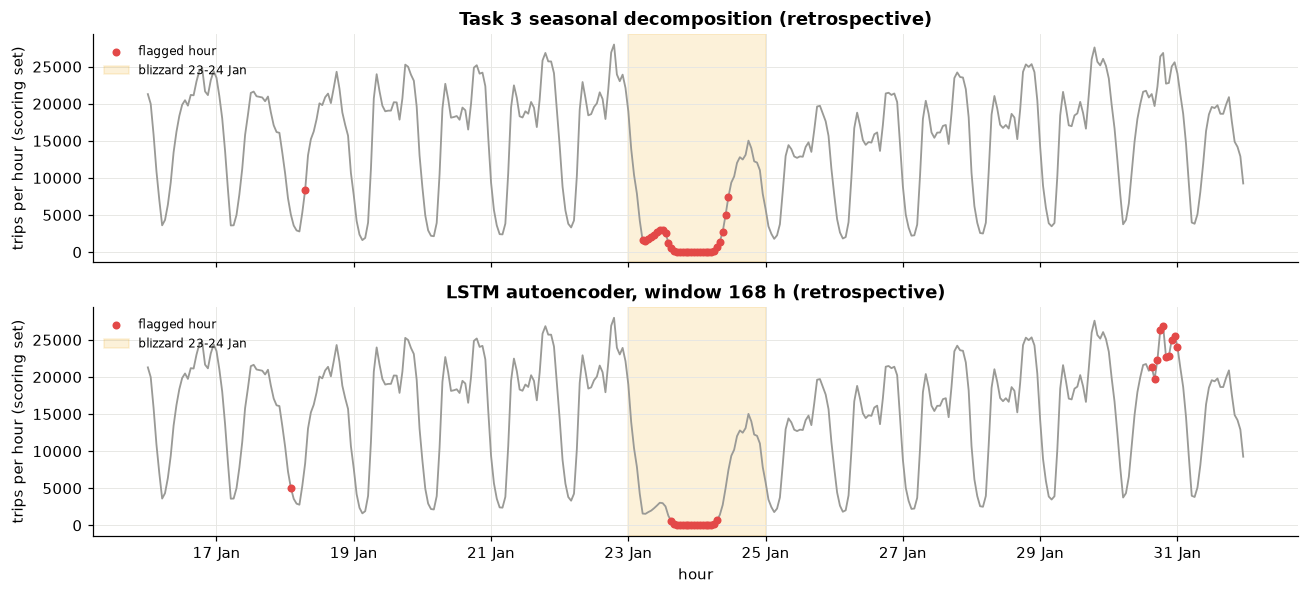

In [41]:
hourly = pd.read_parquet(K28_DIR / "hourly_scores.parquet")
window = hourly.loc["2016-01-16":"2016-01-31"]
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for ax, flag, title in [(axes[0], "flag_decomposition", "Task 3 seasonal decomposition (retrospective)"),
                        (axes[1], "flag_lstm_retro", "LSTM autoencoder, window 168 h (retrospective)")]:
    ax.plot(window.index, window["trips"], color=GREY, lw=1.2)
    hit = window[window[flag]]
    ax.scatter(hit.index, hit["trips"], color=RED, s=18, zorder=3, label="flagged hour")
    ax.axvspan(pd.Timestamp("2016-01-23"), pd.Timestamp("2016-01-25"), color=YELLOW, alpha=0.15, label="blizzard 23-24 Jan")
    ax.set_ylabel("trips per hour (scoring set)")
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper left", fontsize=8)
axes[1].set_xlabel("hour")
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout()
plt.show()

In [42]:
pd.read_csv(K28_DIR / "kh_seed_stability.csv").pivot(index="pair", columns="score", values="top1_overlap").round(1)

score,causal,retro
pair,,
42-43,63.80,60.30
42-44,76.20,56.50
43-44,80.80,80.20


In [43]:
lstm_w = pd.read_csv(K28_DIR / "kh_lstm_window.csv").set_index("window_h")
lstm_w.index = [f"LSTM AE retro, window {w} h, retrained" for w in lstm_w.index]
ref = hourly_cmp.loc[["Task 3 decomposition (retro)", "LSTM AE retro"], ["flagged_fit", "flagged_holdout", "event_hours_flagged_pct", "blizzard_flagged_pct", "flagged_on_events_pct"]]
ref = ref.rename(index={"LSTM AE retro": "LSTM AE retro, window 168 h (model above)"})
pd.concat([ref, lstm_w[ref.columns]]).round(1)


,flagged_fit,flagged_holdout,event_hours_flagged_pct,blizzard_flagged_pct,flagged_on_events_pct
Task 3 decomposition (retro),132,33,19.30,64.60,68.50
"LSTM AE retro, window 168 h (model above)",132,65,17.10,35.40,50.80
"LSTM AE retro, window 24 h, retrained",132,128,12.00,14.60,26.90
"LSTM AE retro, window 72 h, retrained",132,134,21.40,31.20,47.00
"LSTM AE retro, window 168 h, retrained",132,25,12.30,41.70,45.90


In this configuration, on a single city-wide hourly series, the LSTM autoencoder did not beat the Task 3 methods. In the retrospective comparison, the share of flagged hours that coincide with an event is 68.5% for the decomposition and 50.8% for the LSTM; the LSTM caught 35.4% of the blizzard hours against 64.6%. In the real-time comparison the LSTM is also behind (46.7 vs 65.0). The LSTM produced more alarms in the holdout (65 vs 33).

The plot shows this over a single week. The decomposition flagged both the collapse during the blizzard and the recovery. The LSTM flagged only the bottom of the collapse and, a week later, counted an ordinary Saturday-night peak as anomalous. The 168-hour window has seen too few examples to reconstruct this peak.

On the NAB windows the real-time LSTM caught the blizzard window and the Task 3 trailing window did not. This alone does not count as a gain: the trailing window is in its warm-up period for the first four weeks and produces no score for that window at all. Wu and Keogh (2021) show that such single-window differences are misleading in time-series comparisons.

I also tested the window length: I retrained the same LSTM with 24-, 72- and 168-hour windows (last table). In no window did the LSTM beat the Task 3 decomposition: the share of flagged hours that coincide with an event is between 26.9 and 47.0 (decomposition 68.5), and it caught at most 41.7% of the blizzard hours (decomposition 64.6). The 72-hour window covers slightly more event hours (21.4 vs 19.3), but its precision is low and it produces 134 alarms in the holdout. Retraining the 168-hour window with the same settings also gave a different result from the model above (event share 45.9 vs 50.8, holdout alarms 25 vs 65), which is consistent with the sensitivity in the seed table.

The seed table shows the overlap of the hours flagged by the same LSTM trained with three different seeds. In the retrospective version the worst pair is 56.5%; the model is sensitive to the seed, which limits the reliability of its results.

### 5.7 Summary of the comparison

| Anomaly type | Winner | Evidence |
|---|---|---|
| Small fare, duration and distance inconsistencies | Models (+40 to +85 points) | 5.1, E3 |
| Large errors ($25, 60 minutes, duration ×0.2) | Equal | 5.1, E3 |
| Undercharging | Models | 5.1, new families |
| Rate-code misuse | XGBoost; the autoencoder is behind Task 3 | 5.1 |
| Tip inflation | Task 3 | 5.1, new families |
| Errors that need route information | Neither | 5.1, new families |
| Daylight saving time error | Autoencoder and XGBoost duration; the Task 3 union is close with a wider budget | 5.2 |
| Legitimate congestion (false alarm) | Models produce fewer false alarms; the autoencoder's tolerance is about 15 minutes wider | 5.1, 4.2 |
| Event detection on the hourly series | Task 3 | 5.6 |

## 6. Manual inspection of anomaly examples

### 6.1 Top 10 trips of each model

Without ground truth, the most important step is looking at the flagged trips by hand. For each model I selected the 10 highest-scoring trips in the training-period part of the scoring set and retrieved their raw records: distance, duration, average speed, fare, the fare expected under the official tariff, rate code, payment type and tip. To each row I added the rubric label and a short reason code derived from the raw record with simple checks. The reason code states what an analyst would note first when looking at the record; "none of the simple checks" marks trips where none of the simple checks fires and the inconsistency only appears when several columns are read together.

In [44]:
KEY = ["tpep_pickup_datetime", "PULocationID", "DOLocationID", "total_amount", "VendorID"]
rubric_pool = pd.read_parquet(K28_DIR / "kj2_rubric_v2_pool.parquet").drop_duplicates(KEY)
fit_keyed = fit.merge(rubric_pool[KEY + ["raw_distance", "dur_min_raw", "mph", "raw_fare", "official_expected_fare", "RatecodeID",
                                         "payment_type", "extra", "tolls_amount", "tip_amount", "label_v2"]], on=KEY, how="left")

def reason(r):
    """Short reason code read from the raw record (what an analyst would note first)."""
    out = []
    if r.dur_min_raw > 240: out.append("duration > 4 h")
    if r.mph > 80: out.append("speed > 80 mph")
    if r.raw_distance < 0.05: out.append("distance ~0")
    if r.RatecodeID == 5: out.append("negotiated fare")
    if r.RatecodeID == 2 and r.trip_segment != "jfk": out.append("JFK flat fare off JFK")
    if r.RatecodeID == 99: out.append("invalid rate code")
    if r.payment_type in (3, 4): out.append("no charge / dispute")
    if r.raw_fare <= 0: out.append("fare <= 0")
    if r.official_expected_fare > 0 and r.raw_fare > 2 * r.official_expected_fare + 5: out.append("fare >> tariff")
    if r.official_expected_fare > 0 and r.raw_fare < 0.5 * r.official_expected_fare - 2: out.append("fare << tariff")
    if r.trip_segment in ("unknown", "outside_nyc"): out.append(r.trip_segment)
    return "; ".join(out) or "none of the simple checks"

def top10(model):
    t = fit_keyed.nlargest(10, f"score_{model}").copy()
    t["reason code"] = t.apply(reason, axis=1)
    cols = ["tpep_pickup_datetime", "trip_segment", "raw_distance", "dur_min_raw", "mph", "raw_fare", "official_expected_fare",
            "RatecodeID", "payment_type", "tip_amount", "label_v2", "reason code"]
    return t[cols].rename(columns={"tpep_pickup_datetime": "pickup", "raw_distance": "miles", "dur_min_raw": "minutes",
                                   "raw_fare": "fare", "official_expected_fare": "tariff fare", "label_v2": "rubric label"}).round({"miles": 2, "minutes": 1, "mph": 1, "fare": 2, "tariff fare": 2})

coverage = pd.DataFrame({m: [fit_keyed.nlargest(10, f"score_{m}")["label_v2"].notna().sum()] for m in MODELS6}, index=["top-10 rows with raw record"])
coverage

,IF numeric,LOF,OCSVM,XGB fare,XGB duration,AE
top-10 rows with raw record,10,10,10,10,10,10


The raw record was found for all top-10 trips.

#### Isolation Forest

In [45]:
top10("IF numeric")

,pickup,trip_segment,miles,minutes,mph,fare,tariff fare,RatecodeID,payment_type,tip_amount,rubric label,reason code
1019785,2016-05-31 22:30:27,city,0.26,27.70,0.60,16.00,16.35,1.00,1.00,18.00,congestion,none of the simple checks
748509,2016-01-12 07:59:15,city,0.01,0.60,0.90,2.50,2.82,1.00,2.00,0.00,cancelled micro-trip,distance ~0
716457,2015-12-23 07:24:18,city,0.00,0.10,0.00,2.50,2.53,1.00,1.00,3.00,cancelled micro-trip,distance ~0
464755,2015-08-13 07:37:28,city,0.00,0.20,0.00,2.50,2.61,1.00,1.00,12.00,cancelled micro-trip,distance ~0
434502,2015-07-27 20:13:04,city,0.80,28.40,1.70,36.60,16.68,1.00,1.00,0.00,billing irregularity,none of the simple checks
714220,2015-12-21 22:30:34,city,0.04,12.20,0.20,8.50,8.58,1.00,1.00,6.00,congestion,distance ~0
211612,2015-04-10 07:36:59,city,0.00,0.20,0.00,2.50,2.58,1.00,1.00,8.00,cancelled micro-trip,distance ~0
772130,2016-01-25 21:12:11,lga,11.56,84.00,8.30,59.00,44.48,1.00,1.00,13.17,legitimate but rare,none of the simple checks
538128,2015-09-22 07:18:41,city,0.01,3.00,0.20,3.50,3.98,1.00,2.00,0.00,congestion,distance ~0
526118,2015-09-16 09:43:53,city,0.34,27.90,0.70,16.50,16.43,1.00,1.00,3.46,congestion,none of the simple checks


The Isolation Forest top 10 contains four cancelled micro-trips (distance near zero, fare equal to the $2.50 initial charge) and four congestion trips. The congestion trips last 27.7 minutes over 0.26 miles with a fare fully consistent with the tariff ($16 vs $16.35); they are very slow but their billing is fine. One LaGuardia trip is legitimate but rare. The only billing irregularity is $36.60 for 0.8 miles, twice the tariff. Isolation Forest finds what is extreme in a single column: zero distance or very low speed. These are mostly either micro-trips that Task 2 already knows about or legitimate slow trips.

#### LOF

In [46]:
top10("LOF")

,pickup,trip_segment,miles,minutes,mph,fare,tariff fare,RatecodeID,payment_type,tip_amount,rubric label,reason code
310798,2015-05-26 04:42:01,city,7.58,497.00,0.90,256.00,251.00,1.00,2.00,0.00,data error,duration > 4 h
25789,2015-01-13 19:10:56,city,32.90,0.00,inf,2.50,84.75,1.00,3.00,0.00,data error,speed > 80 mph; no charge / dispute; fare << tariff
138253,2015-03-07 01:21:41,city,2.00,218.10,0.60,113.00,111.57,1.00,2.00,0.00,billing irregularity,none of the simple checks
243285,2015-04-24 17:07:40,city,26.60,43.10,37.00,2.50,69.00,1.00,1.00,25.00,billing irregularity,fare << tariff
93714,2015-02-14 21:18:48,jfk,24.30,39.20,37.20,2.50,63.25,1.00,2.00,0.00,billing irregularity,fare << tariff
463457,2015-08-12 15:13:29,jfk,21.40,70.80,18.10,2.50,56.00,1.00,2.00,0.00,billing irregularity,fare << tariff
771541,2016-01-25 16:31:59,city,10.63,211.90,3.00,115.00,108.43,1.00,1.00,0.00,billing irregularity,none of the simple checks
42730,2015-01-21 14:01:03,city,19.70,17.70,66.90,2.50,51.75,1.00,3.00,0.00,billing irregularity,no charge / dispute; fare << tariff
258328,2015-05-01 13:33:25,jfk,21.10,114.00,11.10,6.50,59.50,1.00,2.00,0.00,billing irregularity,fare << tariff
671374,2015-11-27 17:20:26,outside_nyc,4.00,9.20,25.90,85.50,12.50,1.00,4.00,0.00,billing irregularity,no charge / dispute; fare >> tariff; outside_nyc


All of the LOF top 10 are real anomalies. Four trips went 20–27 miles and paid only $2.50, and one went 21 miles and paid $6.50; under the tariff they should have paid $51–69. Two lasted for hours with a fare that grew with the duration: 218 minutes and $113 for 2 miles, and 212 minutes and $115 for 10.6 miles; most likely a meter left running. One is $85.50 for 4 miles outside NYC with payment type dispute (4). Two are clear data errors: 497 minutes for 7.6 miles and 0 minutes for 32.9 miles; the speed of the last one is infinite. LOF's local density measure finds trips with a long distance but a fare equal to the initial charge alone within their own distance group.

#### One-Class SVM

In [47]:
top10("OCSVM")

,pickup,trip_segment,miles,minutes,mph,fare,tariff fare,RatecodeID,payment_type,tip_amount,rubric label,reason code
138253,2015-03-07 01:21:41,city,2.00,218.10,0.60,113.00,111.57,1.00,2.00,0.00,billing irregularity,none of the simple checks
310798,2015-05-26 04:42:01,city,7.58,497.00,0.90,256.00,251.00,1.00,2.00,0.00,data error,duration > 4 h
25789,2015-01-13 19:10:56,city,32.90,0.00,inf,2.50,84.75,1.00,3.00,0.00,data error,speed > 80 mph; no charge / dispute; fare << tariff
243285,2015-04-24 17:07:40,city,26.60,43.10,37.00,2.50,69.00,1.00,1.00,25.00,billing irregularity,fare << tariff
42730,2015-01-21 14:01:03,city,19.70,17.70,66.90,2.50,51.75,1.00,3.00,0.00,billing irregularity,no charge / dispute; fare << tariff
771541,2016-01-25 16:31:59,city,10.63,211.90,3.00,115.00,108.43,1.00,1.00,0.00,billing irregularity,none of the simple checks
671374,2015-11-27 17:20:26,outside_nyc,4.00,9.20,25.90,85.50,12.50,1.00,4.00,0.00,billing irregularity,no charge / dispute; fare >> tariff; outside_nyc
729000,2015-12-31 20:24:55,city,14.20,178.70,4.80,103.00,91.87,1.00,2.00,0.00,congestion,none of the simple checks
93714,2015-02-14 21:18:48,jfk,24.30,39.20,37.20,2.50,63.25,1.00,2.00,0.00,billing irregularity,fare << tariff
463457,2015-08-12 15:13:29,jfk,21.40,70.80,18.10,2.50,56.00,1.00,2.00,0.00,billing irregularity,fare << tariff


Nine of the OCSVM top 10 are the same trips as the LOF top 10. The only different trip lasted 179 minutes over 14.2 miles on New Year's Eve; the rubric counts it as congestion and its fare is consistent with the tariff. The top 10 contains nine real anomalies. That the tops of LOF and OCSVM overlap this much shows that both find trips that are "isolated within their own group".

#### XGBoost fare

In [48]:
top10("XGB fare")

,pickup,trip_segment,miles,minutes,mph,fare,tariff fare,RatecodeID,payment_type,tip_amount,rubric label,reason code
702343,2015-12-16 04:24:15,city,0.40,2.90,8.20,300.00,3.97,5.00,3.00,0.00,billing irregularity,negotiated fare; no charge / dispute; fare >> tariff
218046,2015-04-13 03:24:59,city,0.00,0.80,0.00,360.00,2.92,5.00,3.00,0.00,data error,distance ~0; negotiated fare; no charge / dispute; fare >> tariff
851290,2016-03-04 23:14:09,outside_nyc,29.80,85.30,21.00,0.00,77.00,5.00,1.00,72.00,data error,negotiated fare; fare <= 0; fare << tariff; outside_nyc
765824,2016-01-19 22:47:16,outside_nyc,30.90,41.50,44.70,0.00,79.75,5.00,1.00,220.00,data error,negotiated fare; fare <= 0; fare << tariff; outside_nyc
984745,2016-05-11 16:12:42,lga,20.90,45.70,27.50,0.00,54.75,5.00,1.00,0.00,data error,negotiated fare; fare <= 0; fare << tariff
729325,2015-12-28 10:29:15,outside_nyc,0.00,0.30,0.00,0.01,2.67,5.00,1.00,0.00,cancelled micro-trip,distance ~0; negotiated fare; outside_nyc
631196,2015-11-08 04:12:45,outside_nyc,32.10,67.50,28.50,0.00,82.75,5.00,1.00,0.00,data error,negotiated fare; fare <= 0; fare << tariff; outside_nyc
591544,2015-10-20 06:03:50,city,0.00,0.70,0.00,200.00,2.83,5.00,4.00,0.00,data error,distance ~0; negotiated fare; no charge / dispute; fare >> tariff
643454,2015-11-15 03:17:53,city,0.10,1.00,5.90,100.00,3.01,5.00,3.00,0.00,billing irregularity,negotiated fare; no charge / dispute; fare >> tariff
955136,2016-04-28 04:55:38,city,2.10,0.90,145.40,240.00,7.75,5.00,3.00,0.00,data error,speed > 80 mph; negotiated fare; no charge / dispute; fare >> tariff


All of the XGBoost fare top 10 are negotiated-fare (code 5) trips, and all are real anomalies. Their fares are entirely unrelated to distance: $300 for 0.4 miles, $360 for zero distance, $0 for 30 miles. Some have payment type "no charge" or "dispute", some have tips of $72 and $220. The model predicts the fare of these trips from the tariff, and the difference from the actual fare is very large. All 10 trips could also be caught by the Task 2 negotiated-fare and fare rules. In 3.9 I showed that XGBoost fare weakens at a narrow budget; the reason is visible here. The top of the ranking is full of large errors a rule could catch.

#### XGBoost duration

In [49]:
top10("XGB duration")

,pickup,trip_segment,miles,minutes,mph,fare,tariff fare,RatecodeID,payment_type,tip_amount,rubric label,reason code
440994,2015-07-31 04:52:10,unknown,0.00,240.00,0.00,15.95,122.50,99.00,1.00,0.00,data error,distance ~0; invalid rate code; fare << tariff; unknown
441362,2015-07-31 02:41:22,unknown,0.00,240.00,0.00,13.35,122.50,99.00,1.00,0.00,data error,distance ~0; invalid rate code; fare << tariff; unknown
417807,2015-07-17 17:55:48,unknown,0.00,240.00,0.00,11.57,122.50,99.00,1.00,0.00,data error,distance ~0; invalid rate code; fare << tariff; unknown
767323,2016-01-21 20:04:30,city,0.00,182.90,0.00,52.00,93.97,2.00,1.00,10.56,data error,distance ~0; JFK flat fare off JFK
389008,2015-07-03 10:42:26,jfk,0.00,116.10,0.00,52.00,60.54,2.00,2.00,0.00,data error,distance ~0
523218,2015-09-14 20:49:19,jfk,0.00,88.50,0.00,52.00,46.73,2.00,2.00,0.00,data error,distance ~0
963954,2016-05-02 11:37:44,unknown,0.00,109.90,0.00,12.40,57.47,1.00,2.00,0.00,data error,distance ~0; fare << tariff; unknown
750745,2016-01-11 20:20:25,outside_nyc,0.05,147.20,0.00,2.50,76.08,1.00,1.00,88.00,billing irregularity,fare << tariff; outside_nyc
584480,2015-10-16 16:40:39,city,0.00,91.50,0.00,60.00,48.26,5.00,1.00,15.00,data error,distance ~0; negotiated fare
307421,2015-05-24 01:13:19,city,0.20,128.30,0.10,2.50,66.63,1.00,2.00,0.00,billing irregularity,fare << tariff


All of the XGBoost duration top 10 are real anomalies, mostly data errors. Three trips are in an unknown zone, with an invalid rate code (99), zero distance and a duration of exactly 240 minutes; this repeated value suggests a recording error. Three trips were recorded with the JFK flat fare ($52) but have zero distance and last 88–183 minutes. Because the model predicts duration from distance, every record with zero distance that lasts for hours rises to the top.

#### Autoencoder

In [50]:
top10("AE")

,pickup,trip_segment,miles,minutes,mph,fare,tariff fare,RatecodeID,payment_type,tip_amount,rubric label,reason code
310798,2015-05-26 04:42:01,city,7.58,497.00,0.90,256.00,251.00,1.00,2.00,0.00,data error,duration > 4 h
25789,2015-01-13 19:10:56,city,32.90,0.00,inf,2.50,84.75,1.00,3.00,0.00,data error,speed > 80 mph; no charge / dispute; fare << tariff
138253,2015-03-07 01:21:41,city,2.00,218.10,0.60,113.00,111.57,1.00,2.00,0.00,billing irregularity,none of the simple checks
671374,2015-11-27 17:20:26,outside_nyc,4.00,9.20,25.90,85.50,12.50,1.00,4.00,0.00,billing irregularity,no charge / dispute; fare >> tariff; outside_nyc
78720,2015-02-08 00:11:25,city,13.50,52.80,15.30,2.50,36.25,1.00,1.00,43.30,billing irregularity,fare << tariff
555460,2015-10-01 17:28:15,city,9.30,82.60,6.80,2.50,43.78,1.00,3.00,0.00,billing irregularity,no charge / dispute; fare << tariff
771541,2016-01-25 16:31:59,city,10.63,211.90,3.00,115.00,108.43,1.00,1.00,0.00,billing irregularity,none of the simple checks
507353,2015-09-06 04:29:33,city,11.00,37.00,17.80,2.50,30.00,1.00,2.00,0.00,billing irregularity,fare << tariff
47276,2015-01-23 14:01:36,city,9.80,66.30,8.90,2.50,35.64,1.00,3.00,0.00,billing irregularity,no charge / dispute; fare << tariff
228797,2015-04-18 00:16:47,city,11.00,43.40,15.20,5.00,30.00,1.00,1.00,1.89,billing irregularity,fare << tariff


All of the autoencoder top 10 are real anomalies. The first three are the data errors and the meter left running that are also at the very top for LOF and OCSVM. Five of the remaining seven travelled 9–14 miles and paid $2.50 or $5; two of these have payment type "no charge" (3). The other two are the 212-minute trip also found by LOF and the disputed trip outside NYC. Trip 78720 is especially instructive: 13.5 miles, 53 minutes, a $2.50 fare but a $43.30 tip. The total is close to the tariff; the fare was most likely entered in the tip field. Neither distance, nor duration, nor tip rate shows this on its own; the autoencoder found it from the inconsistency between the three measurements.

### 6.2 What I take from the top 10s

- The top 10 of the five models other than Isolation Forest are almost entirely real anomalies (10/10 for LOF, XGBoost fare, XGBoost duration and the autoencoder, 9/10 for OCSVM). For Isolation Forest the ratio is 5/10, and four of those are micro-trips Task 2 already knows about.
- The models typically find four kinds of records: a payment equal to the initial charge on a long trip (LOF, OCSVM, autoencoder), a meter left running for hours (LOF, OCSVM, autoencoder), a negotiated fare unrelated to distance (XGBoost fare), and a zero-distance record lasting for hours (XGBoost duration).
- Most of the records at the very top are large errors that the Task 2 rules could also catch. The real contribution of the models is further down the ranking, in small inconsistencies the rules cannot see. I measure this with the label composition in 6.3 and with the "rules-first" queue in Section 8.

### 6.3 Label composition of all flagged trips

The top 10 is a small sample. I applied the rubric to all trips flagged in the training period by any model or by Task 3 (76,697) and to 2,000 unflagged control trips.

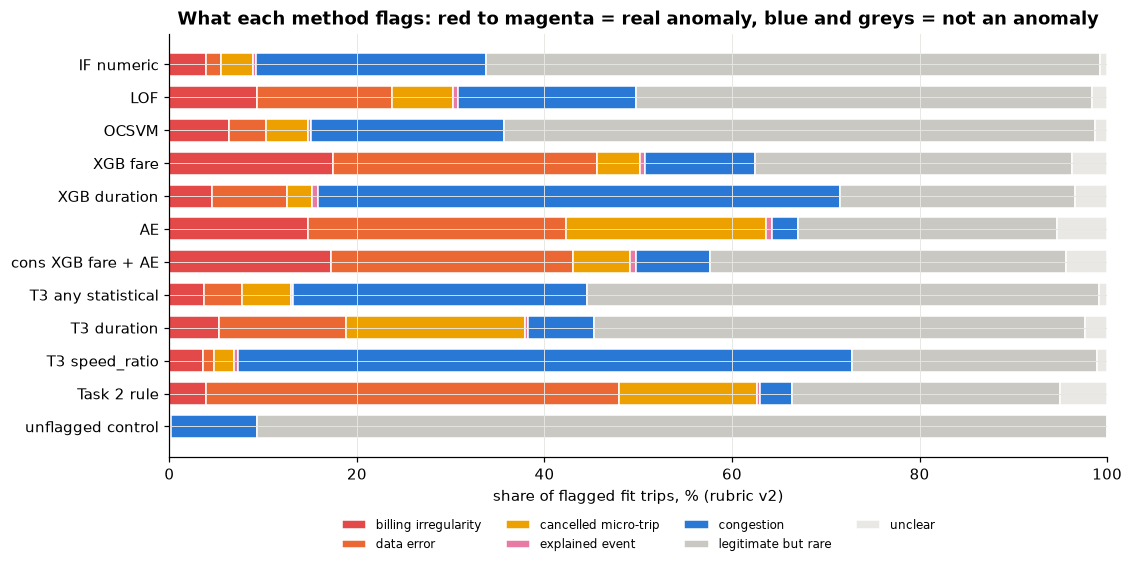

In [51]:
labels = pd.read_csv(K28_DIR / "kj2_group_labels.csv").set_index("group")
groups_show = MODELS6 + ["cons XGB fare + AE", "T3 any statistical", "T3 duration", "T3 speed_ratio", "Task 2 rule", "unflagged control"]
cats = ["billing irregularity", "data error", "cancelled micro-trip", "explained event", "congestion", "legitimate but rare", "unclear"]
colors = [RED, ORANGE, YELLOW, MAGENTA, BLUE, "#c9c8c3", "#e9e8e4"]
fig, ax = plt.subplots(figsize=(11, 5))
left = np.zeros(len(groups_show))
for cat, col in zip(cats, colors):
    vals = labels.loc[groups_show, cat].to_numpy()
    ax.barh(groups_show, vals, left=left, color=col, edgecolor="white", linewidth=1, label=cat, height=0.7)
    left += vals
ax.invert_yaxis()
ax.set_xlabel("share of flagged fit trips, % (rubric v2)")
ax.set_title("What each method flags: red to magenta = real anomaly, blue and greys = not an anomaly")
ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

In [52]:
pd.read_csv(K28_DIR / "kl_rubric_without_rules.csv").set_index("source")[["n (not rule-flagged)", "real %", "CI low", "CI high", "billing %", "congestion %"]].round(1)

,n (not rule-flagged),real %,CI low,CI high,billing %,congestion %
source,,,,,,
IF numeric,9353,4.20,3.80,4.60,3.60,26.00
LOF,7830,10.50,9.80,11.20,9.30,25.20
OCSVM,8791,7.00,6.50,7.60,6.30,23.00
XGB fare,6268,21.40,20.40,22.50,20.40,20.10
XGB duration,9353,5.50,5.00,5.90,4.50,66.00
AE,4224,23.60,22.30,24.90,21.80,6.70
cons XGB fare + AE,6280,20.90,19.90,21.90,19.70,13.20
T3 any statistical,35272,3.50,3.30,3.70,3.20,36.60
T3 duration,4711,4.70,4.10,5.30,3.60,11.50


The real-anomaly share (the categories from red to pink) is 64.3% for the autoencoder, 49.8% for the consensus and 50.7% for XGBoost fare. It is much lower in the geometry family: LOF 30.8%, OCSVM 15.2%, Isolation Forest 9.2%. The Task 3 union flag is at 13.2%. In the unflagged control group the real-anomaly share is 0.2%, so the rubric does not count random trips as anomalies.

The blue part is congestion. 55.7% of the XGBoost duration flags and 65.5% of the Task 3 speed-ratio flags are congestion. These two methods largely find the same thing: slow but legitimate trips. For the autoencoder this share is 2.8%.

These shares include trips caught by the Task 2 rules. The second table shows the shares after removing the rule-flagged trips: autoencoder 23.6%, XGBoost fare 21.4%, consensus 20.9%, Task 3 union 3.5%. The models' confidence intervals do not overlap with that of Task 3 (those of the autoencoder and XGBoost fare do overlap with each other). The models' advantage persists beyond the rules, and almost all of the remaining real anomalies are billing irregularities.

### 6.4 Flagged trips on the distance–fare plane

To visualise which trips the models flag, I plotted the E2 trips by distance and fare. The dashed line is the official tariff without waiting charges; normal trips lie above this line by the amount of their slow minutes.

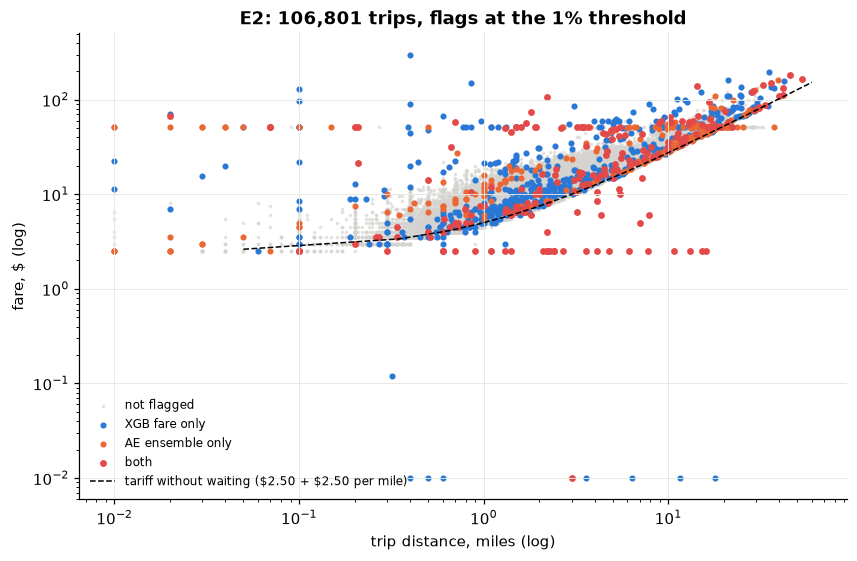

In [53]:
df2 = pd.read_parquet(K28_DIR / "session_state" / "df2.parquet", columns=["trip_distance", "fare_amount", "duration_min"])
flag_ae = live_e2["AE 3-seed ens"] > thresholds["p99"]["AE 3-seed ens"]
flag_xgb = live_e2["XGB fare"] > thresholds["p99"]["XGB fare log"]
ok = (df2["trip_distance"] > 0).to_numpy() & (df2["fare_amount"] > 0).to_numpy()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(df2.loc[ok & ~flag_ae & ~flag_xgb, "trip_distance"], df2.loc[ok & ~flag_ae & ~flag_xgb, "fare_amount"], s=2, color="#d4d3cf", alpha=0.5, label="not flagged")
ax.scatter(df2.loc[ok & flag_xgb & ~flag_ae, "trip_distance"], df2.loc[ok & flag_xgb & ~flag_ae, "fare_amount"], s=9, color=BLUE, label="XGB fare only")
ax.scatter(df2.loc[ok & flag_ae & ~flag_xgb, "trip_distance"], df2.loc[ok & flag_ae & ~flag_xgb, "fare_amount"], s=9, color=ORANGE, label="AE ensemble only")
ax.scatter(df2.loc[ok & flag_ae & flag_xgb, "trip_distance"], df2.loc[ok & flag_ae & flag_xgb, "fare_amount"], s=12, color=RED, label="both")
d = np.linspace(0.05, 60, 200)
ax.plot(d, 2.5 + 2.5 * d, color="black", lw=1, ls="--", label="tariff without waiting (\\$2.50 + \\$2.50 per mile)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("trip distance, miles (log)")
ax.set_ylabel("fare, $ (log)")
ax.set_title(f"E2: {ok.sum():,} trips, flags at the 1% threshold")
ax.legend(frameon=False, fontsize=8)
plt.show()

The grey cloud forms a narrow band above the tariff line. The flagged trips lie outside this band, but in different places:

- Red points (flagged by both models) form a horizontal line at $2.50 between 2 and 20 miles: the initial charge on a long trip. The others lie far above the band, trips that are far too expensive for their distance.
- Orange points (autoencoder only) form a horizontal line at $52: the JFK flat fare applied to short trips.
- Blue points (XGBoost fare only) also cluster right at the edge of the band. These are small deviations from the tariff; XGBoost fare's sensitivity to small errors shows here, but its false congestion alarms also come from this region.
- The $0.01 fares at the bottom and the near-zero distances on the far left are data errors.

### 6.5 How reliable is the rubric: blind labelling

To validate the rubric labels, I labelled 60 trips blind. I selected the trips so that each rubric label had about 8 of them; the labelling sheet showed neither the rubric label nor the expected fare computed by the rubric. As a second independent rater, I had a language model label the same sheet. I measured agreement with Cohen's κ and a 2,000-replicate bootstrap confidence interval. Before seeing the results I wrote this rule: if the binary κ (real anomaly / not) is below 0.6, the rubric-based precision figures are reported as "indicative".

In [54]:
blind = pd.read_csv(K28_DIR / "kj3c_blind_agreement_60.csv")
REAL = {"billing irregularity", "data error", "cancelled micro-trip", "explained event"}
binary = blind[["label_murat", "label_v2", "label_rater2"]].isin(REAL)
rng = np.random.default_rng(42)

def kappa_ci(a, b, reps=2000):
    boot = [cohen_kappa_score(a[i], b[i]) for i in (rng.integers(0, len(a), len(a)) for _ in range(reps))]
    return np.nanpercentile(boot, [2.5, 97.5])

kappa_rows = []
for x, y, label in [("label_murat", "label_v2", "me vs rubric"), ("label_murat", "label_rater2", "me vs second rater"),
                    ("label_rater2", "label_v2", "second rater vs rubric")]:
    a, b = binary[x].to_numpy(), binary[y].to_numpy()
    lo, hi = kappa_ci(a, b)
    kappa_rows.append({"pair": label, "binary kappa": cohen_kappa_score(a, b), "95% CI": f"{lo:.2f} .. {hi:.2f}",
                       "7-label kappa": cohen_kappa_score(blind[x], blind[y]), "binary agreement %": 100 * (a == b).mean()})
pd.DataFrame(kappa_rows).set_index("pair").round(2)

,binary kappa,95% CI,7-label kappa,binary agreement %
pair,,,,
me vs rubric,0.26,0.06 .. 0.47,0.40,61.67
me vs second rater,0.38,0.16 .. 0.60,0.34,68.33
second rater vs rubric,0.60,0.37 .. 0.79,0.61,80.00


The binary κ between my labels and the rubric is 0.26 [0.06, 0.47]; agreement is weak. It is 0.60 between the second rater and the rubric, and 0.38 between me and the second rater. Following the rule I wrote beforehand, I read all rubric-based precision figures in this notebook as indicative. The injection-based results (lift, gains over Task 3) are not affected by this uncertainty.

To see where the disagreement comes from, I re-examined the 23 trips with a different binary decision in two stages. First I relabelled them without seeing the other labels; then I gave the final label after seeing my first label, the rubric label and the second rater's reasoning. I did not recompute κ = 0.26 after this stage; the adjudication was done to find which rubric rules were wrong.

In [55]:
adj = pd.read_csv(K28_DIR / "adjudication_outcome.csv")
adj["outcome group"] = np.where(adj["outcome"].str.startswith("insan"), "human right (rubric rule wrong)",
                                np.where(adj["outcome"].str.contains("asimetri"), "rubric right (flag not visible on the sheet)", "rubric right"))
RULE_NAMES = [("mph", "speed 2-50 mph, distance > 0 (legitimate)"), ("JFK", "JFK flat rate (code 2) off JFK"),
              ("< 0.5", "negotiated rate (code 5), distance < 0.5 mi"), ("~0", "distance ~0, duration > 20 min or fare > $20"),
              ("olay", "date falls on a known event day"), ("tetik", "no rule fired (unclear)"), ("Veri ", "data validity flag")]
adj["rubric rule"] = adj["rule"].map(lambda r: next(name for key, name in RULE_NAMES if key in r))
adj.pivot_table(index="rubric rule", columns="outcome group", values="adj_id", aggfunc="count", fill_value=0, margins=True, margins_name="total")


outcome group,human right (rubric rule wrong),rubric right,rubric right (flag not visible on the sheet),total
rubric rule,,,,
JFK flat rate (code 2) off JFK,0,2,0,2
data validity flag,2,0,4,6
date falls on a known event day,3,2,0,5
"distance ~0, duration > 20 min or fare > $20",0,1,0,1
"negotiated rate (code 5), distance < 0.5 mi",0,4,0,4
no rule fired (unclear),3,0,0,3
"speed 2-50 mph, distance > 0 (legitimate)",1,1,0,2
total,9,10,4,23


Of the 23 trips, the rubric was right in 10, right in 4 but relying on a flag not visible on the labelling sheet (information asymmetry), and I was right in 9. The rubric's errors concentrate in specific rules: linking a trip to a known event day by its date alone (3 of 5 trips), trips where no rule fired and which stayed "unclear" (3/3), and the amount-mismatch flag on its own. The rules where the rubric was always right are near-zero distance on a negotiated fare (4/4) and the JFK rate code off JFK (2/2). The lack of a "normal" option in the labelling scheme was also a source of error on my side: I labelled near-normal trips as "congestion".

### 6.6 Do the rubric thresholds change the result

The rubric rests on three thresholds: how far the fare may deviate from the tariff (tolerance), below which speed a trip counts as "slow", and the deviation required for a billing irregularity. I tried three values for each threshold and relabelled the E3 0.1% queues under all 27 combinations.

In [56]:
kh6a = pd.read_csv(K28_DIR / "kh6a_rubric_threshold_grid.csv")
kh6a["AE-ens highest"] = kh6a["0.1% real AE-ens"] >= kh6a[["0.1% real XGB log", "0.1% real XGB $"]].max(axis=1)
grid = kh6a.groupby("billing").agg(combinations=("tolerance", "size"), **{c: (c, "mean") for c in ["0.1% real AE-ens", "0.1% real XGB log", "0.1% real XGB $"]},
                                   **{"AE-ens highest": ("AE-ens highest", "sum"), "H2 CI low (min)": ("H2 ci_lo", "min")})
grid.loc["all 27"] = [len(kh6a), np.nan, np.nan, np.nan, kh6a["AE-ens highest"].sum(), kh6a["H2 ci_lo"].min()]
grid.round(1)

,combinations,0.1% real AE-ens,0.1% real XGB log,0.1% real XGB $,AE-ens highest,H2 CI low (min)
billing,,,,,,
"max(10, 50%)",9.00,56.50,44.40,40.70,9.00,4.90
"max(20, 75%)",9.00,38.90,30.60,38.90,9.00,4.90
"max(5, 30%)",9.00,67.60,61.10,43.50,9.00,4.90
all 27,27.00,NaN,NaN,NaN,27.00,4.90


The level of precision depends strongly on the billing threshold: the real-anomaly share of the autoencoder ensemble is 67.6% at the loosest threshold and 38.9% at the strictest. But the ranking is the same in all 27 combinations: the autoencoder ensemble gives the highest or joint-highest share. The congestion trade-off at the 1% budget (more congestion in the XGBoost fare log queue than in the autoencoder ensemble queue) is also positive in every combination, with a worst-case lower confidence bound of 4.9. The rubric's absolute figures are uncertain, but the ranking of the models is robust to the rubric thresholds.

### 6.7 A signal outside the matrix: passenger count and store-and-forward

During manual inspection I noticed that two raw fields appear often among flagged trips: the passenger count and `store_and_fwd_flag`, which shows that a record was sent later after a connection loss. Neither is a model input. I measured on E2 whether they really carry a signal.

In [57]:
df2_meta = pd.read_parquet(K28_DIR / "session_state" / "df2.parquet", columns=["passenger_count", "is_store_forward"])
odd_pax = (df2_meta["passenger_count"].isna() | (df2_meta["passenger_count"] > 6)).to_numpy()   # 0 passengers is stored as missing
saf = df2_meta["is_store_forward"].fillna(False).astype(bool).to_numpy()
is_rule = np.asarray(rule_e2).astype(bool)

def wilson(k, n, z=1.96):
    p = k / n
    centre, half = (p + z * z / (2 * n)) / (1 + z * z / n), z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return 100 * (centre - half), 100 * (centre + half)

sig_rows = []
for name, f in [("AE 3-seed ens", flag_ae), ("XGB fare", flag_xgb)]:
    k, n = int((f & ~is_rule & saf).sum()), int((f & ~is_rule).sum())
    lo, hi = wilson(k, n)
    sig_rows.append({"score": name, "flagged": int(f.sum()), "passenger 0 or >6 among flagged": int((f & odd_pax).sum()),
                     "of which Task 2 rule rows": int((f & odd_pax & is_rule).sum()),
                     "flagged, rule rows excluded": n, "store-and-forward among them": k,
                     "store-and-forward %": 100 * k / n, "95% CI": f"{lo:.1f} .. {hi:.1f}",
                     "base rate % (rule rows excluded)": 100 * saf[~is_rule].mean()})
pd.DataFrame(sig_rows).set_index("score").round(2)


,flagged,passenger 0 or >6 among flagged,of which Task 2 rule rows,"flagged, rule rows excluded",store-and-forward among them,store-and-forward %,95% CI,base rate % (rule rows excluded)
score,,,,,,,,
AE 3-seed ens,1049,5,5,447,15,3.36,2.0 .. 5.5,0.70
XGB fare,1073,10,10,624,16,2.56,1.6 .. 4.1,0.70


E2 contains only 35 trips with a passenger count of 0 or more than 6. Among flagged trips they are far above the base rate, but as the table shows, every flagged one is already a record caught by the Task 2 rules; none of the 25 trips not caught by the rules was flagged. The passenger count adds nothing new to the models or the rules.

Store-and-forward records, on the other hand, remain several times the base rate among flagged trips even after rule-flagged rows are removed (base 0.70%). The counts are small, so the confidence interval is wide, but its lower bound is also above the base rate. Records sent later after a connection loss can have corrupted time or distance information; this field can be used to prioritise alarms or as an input in the next version of the model.

## 7. Robustness

### 7.1 The same threshold across months

I took the thresholds once from the training-period calibration set and looked at how much the models flag in each of the 24 months. If a model generalises, it should flag about 1% every month. Before seeing the results I defined the 0.8–1.25% band as "consistent".

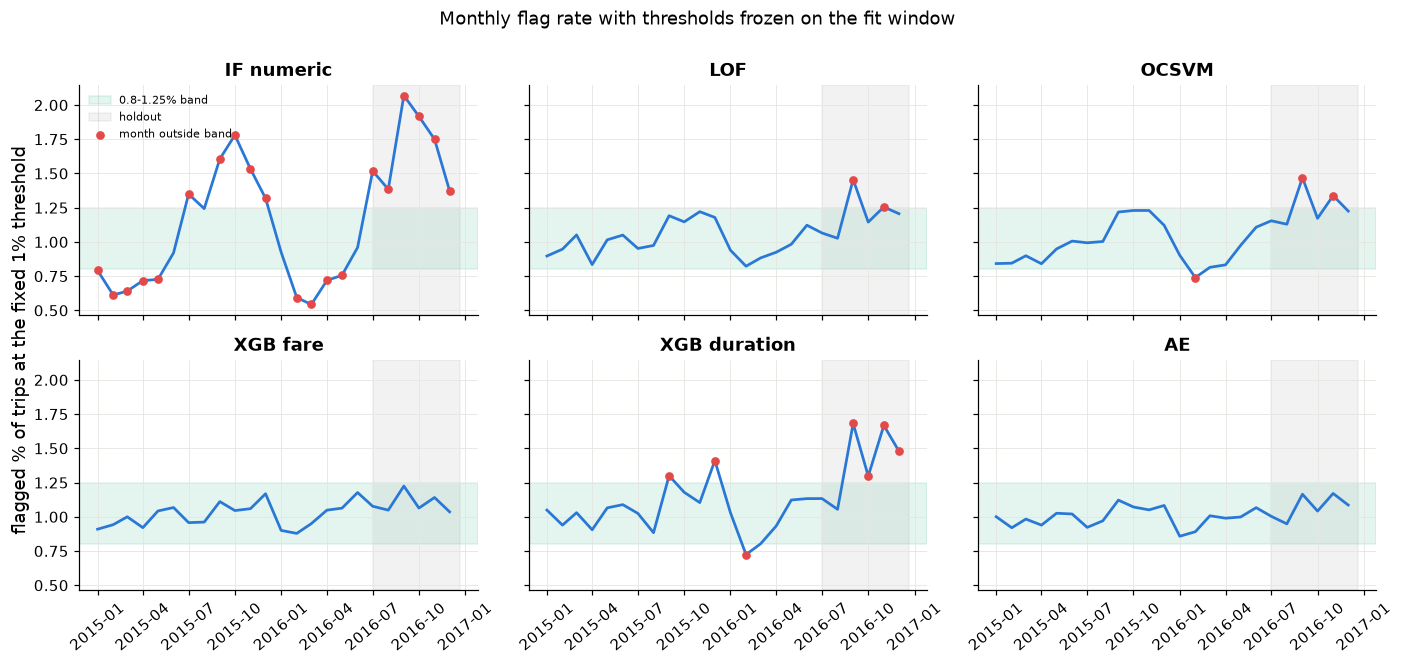

In [58]:
monthly = pd.read_csv(K28_DIR / "ki_monthly_flag_rates.csv")
monthly["date"] = pd.to_datetime(monthly["ym"])
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for ax, m in zip(axes.flat, MODELS6):
    ax.axhspan(0.8, 1.25, color=AQUA, alpha=0.12, label="0.8-1.25% band")
    ax.axvspan(pd.Timestamp("2016-07-01"), monthly["date"].max() + pd.Timedelta(days=20), color=GREY, alpha=0.12, label="holdout")
    ax.plot(monthly["date"], monthly[m], color=BLUE, lw=1.8)
    out = monthly[(monthly[m] < 0.8) | (monthly[m] > 1.25)]
    ax.scatter(out["date"], out[m], color=RED, s=22, zorder=3, label="month outside band")
    ax.set_title(m)
    ax.tick_params(axis="x", rotation=40)
axes[0, 0].legend(frameon=False, fontsize=7, loc="upper left")
fig.supylabel("flagged % of trips at the fixed 1% threshold")
fig.suptitle("Monthly flag rate with thresholds frozen on the fit window", y=1.0)
plt.tight_layout()
plt.show()

In [59]:
pd.read_csv(K28_DIR / "ki_monthly_summary.csv").set_index("index")[
    ["fit months outside 0.8-1.25", "holdout months outside 0.8-1.25", "holdout mean", "mean |month-to-month| in fit"]].round(2)

,fit months outside 0.8-1.25,holdout months outside 0.8-1.25,holdout mean,mean |month-to-month| in fit
index,,,,
IF numeric,14,6,1.67,0.19
LOF,0,2,1.19,0.10
OCSVM,1,2,1.25,0.08
XGB fare,0,0,1.10,0.08
XGB duration,3,4,1.39,0.16
AE,0,0,1.07,0.07
cons XGB fare + AE,0,1,1.13,0.09
T3 any statistical,18,6,4.71,0.43
T3 rule,18,6,1.73,0.40


In [60]:
profile = pd.read_csv(K28_DIR / "ki_monthly_feature_profile.csv").set_index("ym")
profile.loc["2016-04":"2016-12", ["median_speed_ratio", "median_duration", "median_fare"]].T.round(2)

ym,2016-04,2016-05,2016-06,2016-07,2016-08,2016-09,2016-10,2016-11,2016-12
median_speed_ratio,0.98,0.97,0.96,0.99,1.00,0.94,0.94,0.93,0.93
median_duration,11.23,11.55,11.55,11.20,11.20,11.82,11.58,11.72,11.40
median_fare,9.50,10.00,9.50,9.50,9.50,10.00,9.50,10.00,9.50


XGBoost fare and the autoencoder never left the band in any of the 24 months; their holdout averages are 1.10% and 1.07%. Isolation Forest is outside the band in 14 of the 18 training months and rises between July and November in both years: it is seasonal. The seasonal effect comes from raw numeric columns that change with the season, and Isolation Forest looks only at those columns. XGBoost duration is outside the band in 4 of the 6 holdout months.

The rise in the holdout comes from city speed: in the last table the median speed ratio drops to 0.93–0.94 in September–December 2016 (0.99–1.00 in July–August) and the median duration grows. The alarm rate of the traffic-sensitive models (Isolation Forest, XGBoost duration) rises, while XGBoost fare and the autoencoder, which look at fare consistency, stay flat. The Task 3 flags are not at a 1% budget, so their rates in the table cannot be compared directly, but their month-to-month change is much larger than the models' (mean 0.43 points vs 0.07–0.19).

### 7.2 Schema break and vendor

In Task 1 I found that in July 2016 the lat/lon coordinates were removed and replaced by zone IDs. I tested whether this break affects the models: does the change from June to July exceed the largest month-to-month change in the training period? As a placebo I made the same comparison for the June–July 2015 transition.

In [61]:
pd.read_csv(K28_DIR / "ku3a_schema_break.csv").set_index("metric %").round(3)

,Jun->Jul 2016 |d|,Jun->Jul 2015 |d| (placebo),max |d| fit window,break
metric %,,,,
seg_city,0.03,0.32,0.62,False
seg_ewr,0.01,0.03,0.07,False
seg_jfk,0.17,0.06,0.35,False
seg_lga,0.21,0.09,0.41,False
seg_outside_nyc,0.01,0.03,0.07,False
seg_unknown,0.06,0.11,0.30,False
is_zone_unknown,0.06,0.12,0.29,False
is_outside_nyc,0.02,0.04,0.09,False
flag_XGB fare,0.10,0.11,0.27,False


In [62]:
vendor = pd.read_csv(K28_DIR / "ku3b_vendor_month.csv", header=[0], skiprows=[1, 2])
vendor.columns = ["month", "XGB fare v1", "XGB fare v2", "XGB fare v3", "AE v1", "AE v2", "AE v3", "rule v1", "rule v2", "rule v3"]
vendor["rule ratio v1/v2"] = vendor["rule v1"] / vendor["rule v2"]
vendor[vendor["month"].isin([201501, 201502, 201503, 201604, 201605, 201606])][
    ["month", "rule v1", "rule v2", "rule ratio v1/v2", "AE v1", "AE v2", "XGB fare v1", "XGB fare v2", "rule v3"]].set_index("month").round(2)

,rule v1,rule v2,rule ratio v1/v2,AE v1,AE v2,XGB fare v1,XGB fare v2,rule v3
month,,,,,,,,
201501,12.88,1.25,10.31,1.24,0.78,0.99,0.83,NaN
201502,1.74,1.02,1.70,1.11,0.75,1.04,0.85,NaN
201503,1.85,0.96,1.92,1.26,0.73,1.11,0.90,NaN
201604,2.09,1.25,1.67,1.17,0.83,1.13,0.98,NaN
201605,1.98,1.17,1.69,1.19,0.82,1.11,1.02,12.50
201606,1.84,1.59,1.15,1.19,0.96,1.09,1.26,5.56


From June to July 2016 no measure (segment shares, unknown zone, model flag rates, rule flag) jumps by more than the largest monthly change in the training period, and the placebo looks similar. The Task 2 feature pipeline, which is based on zone IDs, absorbed the transition; the models are not affected.

The vendor table shows something else. In January 2015 the rule-flag rate of vendor 1 was 12.88% and that of vendor 2 1.25%: 10.3 times higher. In the following months the ratio falls to 1.2–1.9. This jump is specific to one vendor and most likely comes from that vendor's data pipeline. The model flags are at their usual level in the same month, so the models were not affected by this rule jump. From May 2016 a third vendor with very few trips appears; its trip count is too small for its rates (12.5%, 5.6%) to be meaningful. A vendor-level alarm needs at least a minimum-volume condition.

### 7.3 Region-wise retraining

A natural question is whether the same model is consistent across regions. I retrained XGBoost fare and the autoencoder separately on trips starting in Manhattan only and on trips starting outside Manhattan only (49,933 rows each) and compared them with a global model. To separate how much of the difference in flagged trips between the regional and the global model is a real regional difference and how much is sampling noise, I trained a second global model with the same number of rows; the overlap between the two global models is the noise floor.

In [63]:
ku2 = pd.read_csv(K28_DIR / "ku2_region_refit.csv").rename(columns={"region (E2 rows)": "region"})
ku2b = pd.read_csv(K28_DIR / "ku2b_region_noise_floor.csv")
ku2.merge(ku2b, on=["region", "model"])[["region", "model", "n injected", "overlap region vs global", "noise floor global vs global2",
                                         "gap", "fine lift diff", "verdict"]].set_index(["region", "model"]).round(1)

n injected  overlap region vs global  noise floor global vs global2   gap  fine lift diff                verdict
region        model                                                                                                                     
Manhattan     XGB fare         905                     65.10                          67.70  2.60            0.10  within sampling noise
              AE               905                     71.50                          62.40 -9.10            1.00  within sampling noise
non-Manhattan XGB fare          95                     53.70                          55.80  2.10            5.60  within sampling noise
              AE                95                     54.70                          65.30 10.50          -16.50        region-specific

XGBoost fare is within the noise floor in both regions (differences of 2.6 and 2.1 points): it generalises across regions. The autoencoder is within noise in Manhattan and borderline region-specific outside Manhattan (difference 10.5 points); the small-error lift of the non-Manhattan model is 16.5 points lower. Outside Manhattan there are only 95 injected rows, so the confidence interval of this difference is wide. Still, I think the autoencoder should be used with more care on trips outside Manhattan.

### 7.4 Concentration in segments

The models use a single global threshold, whereas the Task 3 thresholds were segment-wise. I measured the effect of this difference by dividing each segment's flag rate by its base rate.

In [64]:
seg_conc = pd.read_csv(K28_DIR / "ki_segment_concentration.csv").set_index("trip_segment")
seg_conc[MODELS6 + ["T3 any statistical"]]

,IF numeric,LOF,OCSVM,XGB fare,XGB duration,AE,T3 any statistical
trip_segment,,,,,,,
city,0.80,0.70,0.80,0.60,1.00,0.60,1.00
ewr,3.00,5.00,6.40,8.50,1.50,6.00,0.30
jfk,3.30,3.40,3.20,2.80,1.10,5.10,1.00
lga,5.20,2.60,3.60,1.40,0.70,1.00,0.90
outside_nyc,4.50,49.80,13.90,60.00,7.00,36.80,1.70
unknown,0.20,6.10,1.50,10.30,3.30,12.90,0.80


In [65]:
pd.read_csv(K28_DIR / "kr5_segment_thresholds.csv").set_index(["score", "mode"]).round(1)

n  real %  fare-indep %  congestion %  fine lift  max concentration x worst segment
score             mode                                                                                               
XGB fare log      global       1075   14.00         10.00         19.30      95.80                55.70   outside_nyc
                  per-segment  1056   12.70          8.90         21.00      94.70                 1.30           ewr
XGB fare $|resid| global       1075   19.10         15.20          8.40      81.40                72.90   outside_nyc
                  per-segment  1056   16.10         12.50         14.20      85.30                 1.30           ewr
AE 3-seed ens     global       1071   15.20         11.40          7.00      77.10                40.90   outside_nyc
                  per-segment  1056   13.00          9.10         13.30      84.30                 1.30           ewr

In [66]:
zones = pd.read_parquet(K28_DIR / "session_state" / "df2.parquet", columns=["pu_zone_trips"])["pu_zone_trips"].to_numpy(float)
low_volume = zones <= np.nanquantile(zones, 0.10)
pd.DataFrame({"flagged in low-volume pickup zones % (lowest 10% of zone volume)": [100 * low_volume[flag_ae].mean(), 100 * low_volume[flag_xgb].mean()],
              "x base": [low_volume[flag_ae].mean() / low_volume.mean(), low_volume[flag_xgb].mean() / low_volume.mean()]},
             index=["AE 3-seed ens", "XGB fare"]).round(2)


,flagged in low-volume pickup zones % (lowest 10% of zone volume),x base
AE 3-seed ens,19.35,1.93
XGB fare,18.64,1.86


With a global threshold, trips outside NYC are heavily over-represented among the flags: 60 times for XGBoost fare, 49.8 times for LOF, 36.8 times for the autoencoder. Unknown-zone trips are 12.9 times over-represented for the autoencoder. In these segments the context columns are sparse and the fares do not follow the tariff; the models systematically find them unusual. The segment-wise thresholds of Task 3 do not show this concentration (at most 1.7 times). The same effect appears with zone volume: trips from the 10% of pickup zones with the lowest volume are about 1.9 times their base rate among the flags (last table).

Sharing the same total 1% budget across segments in proportion to their size brought the concentration down to 1.3 times for every score. The small-error lift of the autoencoder ensemble rose from 77.1 to 84.3 and precision fell by 2.2 points. This has a cost too: the share of congestion in the queue rose (from 7.0% to 13.3% for the autoencoder ensemble). I recommend a segment-wise budget in production, but the congestion share needs to be among the monitoring metrics.

### 7.5 Trips the injection protocol left out

I had chosen the injection sources among clean trips. This left out trips with an undefined route ratio, airport trips on the standard meter and JFK flat-fare trips. Yet in Section 7.4 I saw that alarms concentrate in these segments. To see whether the results also hold for these trips, I repeated the same injections on source rows drawn from these groups. I also added unknown-zone trips: many context columns are undefined there and stayed undefined in the corrupted rows, so the model sees the same input it would see in production. Next to the small-error lift I also show the congestion control test, because detection and false alarms can rise together in a group.

In [67]:
kh3 = pd.read_csv(K28_DIR / "kh3_injection_excluded_rows.csv").rename(columns={"congestion probe (+30 min, +$15)": "congestion probe"})
show_cols = [(metric, budget, model) for metric in ("mean lift fine", "congestion probe")
             for budget, model in (("0.1%", "AE-ens"), ("0.1%", "XGB fare log"), ("1%", "AE-ens"), ("1%", "XGB fare log"))]
kh3.pivot_table(index="source group", columns=["budget", "model"], values=["mean lift fine", "congestion probe"]).loc[
    kh3["source group"].unique(), show_cols].round(1)


mean lift fine                                  congestion probe                                 
budget                                          0.1%                  1%                          0.1%                  1%             
model                                         AE-ens XGB fare log AE-ens XGB fare log           AE-ens XGB fare log AE-ens XGB fare log
source group                                                                                                                           
clean (original protocol)                      10.00         0.00  60.20        92.00             0.10         0.00   4.70        63.20
route_ratio undefined                           8.90         1.00  47.10        80.00             1.80         0.10   5.00        91.80
airport, standard meter                        12.90        -0.00  61.20        82.00            -0.10        -0.20  27.00        35.90
JFK flat rate (fare_excess undefined)           4.00         0.00  28.10         3.80             2.80         0.00  14.00        97.90
unknown zone                                    7.70         0.40  45.30        84.00            51.50        -0.10  87.80        93.70

At the 0.1% budget, the autoencoder ensemble keeps catching more small errors than XGBoost fare log in the left-out groups too (route ratio undefined 8.9 vs 1.0; airport 12.9 vs 0; unknown zone 7.7 vs 0.4). At 1% XGBoost fare log is ahead. In the unknown zone, however, a weakness of the autoencoder appears: it flags the congestion control test with 51.5 points at 0.1% and 87.8 at 1% (0.1 and 4.7 on clean trips). The speed ratio is undefined in this zone, so the autoencoder cannot explain slowness with the traffic context; unknown-zone trips (about 1.6% of the data) need a separate budget or monitoring. JFK flat-fare trips are a shared blind spot: the fare excess is undefined for these trips, so at 1% the autoencoder produces 28.1 and XGBoost fare log 3.8 lift. Flat-fare trips should be audited with a tariff rule.

### 7.6 How much the alarm list changes on retraining

The last robustness question is overfitting: when the model is retrained, does it flag the same trips? In the stability measure of Section 3 the A and B sides used the same seed. For a seed-sensitive model this measure is optimistic, because in a real retraining the seed changes too. The table below shows both cases side by side in the "rules-first" queue at the 0.1% budget.

In [68]:
kv3 = pd.read_csv(K28_DIR / "kv3_operating_queue_stability.csv")
c1 = pd.read_csv(K28_DIR / "c1_stability.csv")
def parse_pairs(text):
    """Pair overlaps were saved as the repr of a list of numpy floats."""
    return [float(x) for x in text.replace("np.float64(", "").replace(")", "").strip("[]").split(",")]

cold = parse_pairs(c1.loc[c1["budget"] == "0.1%", "cold disjoint pairs"].iloc[0])
stab = kv3[kv3["budget"] == "0.1%"][["model", "pair0", "pair1", "pair2", "min"]].assign(seeds="same seed on both sides").reset_index(drop=True)
stab.loc[len(stab)] = ["AE 3-seed ens", *cold, min(cold), "different seeds on the two sides"]
stab["mean"] = stab[["pair0", "pair1", "pair2"]].mean(axis=1)
stab["alarm list change % (100 - mean)"] = 100 - stab["mean"]
stab.set_index(["model", "seeds"]).round(1)

,,pair0,pair1,pair2,min,mean,alarm list change % (100 - mean)
model,seeds,,,,,,
AE single,same seed on both sides,83.20,73.80,84.10,73.80,80.40,19.60
AE 3-seed ens,same seed on both sides,79.40,86.90,96.30,79.40,87.50,12.50
XGB fare log,same seed on both sides,86.00,85.00,83.20,83.20,84.70,15.30
XGB fare $|resid|,same seed on both sides,77.60,79.40,72.90,72.90,76.60,23.40
AE 3-seed ens,different seeds on the two sides,71.00,90.70,84.10,71.00,81.90,18.10


With the same seed, the worst pair of the autoencoder ensemble is 79.4 and the mean 87.5. With different seeds the mean drops to 81.9 and the worst pair to 71.0. In a realistic retraining, on average 18% of the autoencoder ensemble's alarm list changes, and 29% in the worst case. XGBoost fare log stays at 83.2 with the same seed and its dollar residual at 72.9. To reduce the change in the autoencoder I tried variants that change the training settings (Appendix A), and in Appendix B I tested a retraining method for production: the new model starts from the weights of the previous model instead of from scratch (warm start).

## 8. Business view

### 8.1 Testing the hypotheses on E3

After model selection was finished, and before opening E3, I wrote four hypotheses and then opened E3 once. The tables show two budgets in the "rules-first" queue: 0.1% (108 trips) and 1% (1,078 trips). The real-anomaly share rests on the rubric and should be read as indicative.

In [69]:
e3q = pd.read_csv(K28_DIR / "e3" / "kw1_queue_results.csv")
e3q[e3q["set"] == "E3_fit"][["score", "budget", "k", "real %", "real CI", "real_fare_indep %", "congestion %", "fine lift",
                              "coarse lift", "rate-code", "DST recall %"]].set_index(["budget", "score"]).sort_index().round(1)

k  real %    real CI  real_fare_indep %  congestion %  fine lift  coarse lift  rate-code  DST recall %
budget score                                                                                                                       
0.1%   AE 3-seed ens       108   56.50  47.1-65.5              32.40          2.80      30.50        85.80       6.30         97.70
       AE single           108   48.10  39.0-57.5              24.10          3.70      32.60        88.50       4.20         97.80
       XGB fare $|resid|   108   40.70  31.9-50.2              38.00          0.90       0.90        24.50      28.00          0.40
       XGB fare log        108   44.40  35.4-53.8              25.90          1.90      17.40        66.80      18.90          6.30
1%     AE 3-seed ens      1078   13.80  11.9-16.0              11.00          6.90      76.30        99.00      75.60         99.90
       AE single          1078   12.70  10.9-14.8              10.10          7.40      77.20        99.10      27.90        100.00
       XGB fare $|resid|  1078   18.70  16.5-21.2              15.80          8.30      80.00        93.90      91.70         60.80
       XGB fare log       1078   15.20  13.2-17.5              12.30         17.40      96.00        96.90      82.20         76.70

In [70]:
pd.read_csv(K28_DIR / "e3" / "kw1_hypotheses.csv").set_index("index").round(1)

,estimate,ci_lo,ci_hi,confirmed
index,,,,
H1 0.1% fine lift AE-ens - XGB log > 0,13.00,11.90,14.20,True
H2 1% congestion share XGB log - AE-ens > 0,10.60,8.20,12.90,True
H3a 1% fine lift XGB $ - AE-ens > -5,3.70,2.70,4.70,True
H3b 1% rate-code XGB $ - AE-ens > 0,16.10,13.30,18.90,True
H4 consensus p99 beats T3 union on fine variants (>=6/7),64.00,NaN,NaN,True
H4 AE 3-seed ens p99 beats T3 union on fine variants (>=6/7),33.20,NaN,NaN,True


All four hypotheses held:

- At 0.1%, the autoencoder ensemble catches 13.0 points [11.9, 14.2] more small errors than XGBoost fare log. It is also the score with the highest real-anomaly share (56.5%), but since the 0.1% queue has 108 trips the confidence intervals overlap (XGBoost fare log 35.4–53.8). The decision at this budget rests mainly on the small-error difference and the congestion share.
- At 1%, the congestion share in the XGBoost fare log queue is 10.6 points [8.2, 12.9] higher than in the autoencoder ensemble queue.
- At 1%, the dollar XGBoost residual ($|resid|) does not fall behind the autoencoder ensemble on small errors (+3.7) and is 16.1 points better on rate-code misuse.
- The consensus and the autoencoder ensemble beat the Task 3 union on the small-error variants (Section 5.1).

### 8.2 Which model suits this platform better

The answer depends on the alarm budget. The budget is an operational decision: it sets how many alarms can be reviewed by hand. At the scale of the scoring set there are about 393,000 trips per day; 0.1% means 393 alarms per day and 1% means 3,931.

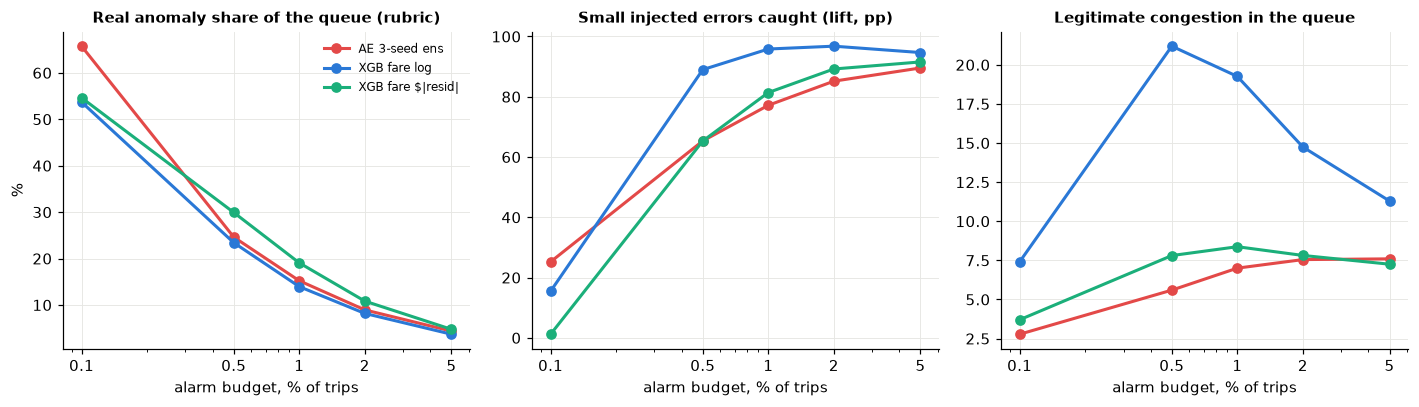

In [71]:
kr4b = pd.read_csv(K28_DIR / "kr4b_budget_table.csv")
kr4b["b"] = kr4b["budget"].str.rstrip("%").astype(float)
show = {"AE 3-seed ens": RED, "XGB fare log": BLUE, "XGB fare $|resid|": AQUA}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
for ax, col, title in zip(axes, ["real %", "fine lift", "congestion %"],
                          ["Real anomaly share of the queue (rubric)", "Small injected errors caught (lift, pp)", "Legitimate congestion in the queue"]):
    for name, color in show.items():
        g = kr4b[kr4b["model"] == name]
        ax.plot(g["b"], g[col], marker="o", lw=2, color=color, label=name)
    ax.set_xscale("log")
    ax.set_xticks([0.1, 0.5, 1, 2, 5], ["0.1", "0.5", "1", "2", "5"])
    ax.set_xlabel("alarm budget, % of trips")
    ax.set_title(title, fontsize=10)
axes[0].set_ylabel("%")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [72]:
kr4b[kr4b["budget"].isin(["0.1%", "1%"])][["model", "budget", "alarms/day", "real %", "fare-indep real %", "congestion %", "fine lift"]].set_index(["budget", "model"]).round(1)

,,alarms/day,real %,fare-indep real %,congestion %,fine lift
budget,model,,,,,
0.1%,XGB fare log,393.10,53.70,21.30,7.40,15.50
1%,XGB fare log,"3,931.20",14.00,10.00,19.30,95.80
0.1%,XGB fare $|resid|,393.10,54.60,38.90,3.70,1.20
1%,XGB fare $|resid|,"3,931.20",19.10,15.20,8.40,81.40
0.1%,AE single,393.10,55.60,17.60,3.70,30.10
1%,AE single,"3,931.20",14.20,10.40,6.90,78.30
0.1%,AE 3-seed ens,393.10,65.70,27.80,2.80,25.20
1%,AE 3-seed ens,"3,931.20",15.20,11.40,7.00,77.20
0.1%,consensus,393.10,50.00,13.00,5.60,42.60


As the budget widens, the real-anomaly share in the queue falls quickly (from 65.7% to 15.2% for the autoencoder ensemble), while detection of small errors rises (from 25.2 to 77.2). Different models stand out at the two budgets:

- 0.1% budget (about 390 alarms per day, a high-precision review queue): the autoencoder ensemble. Highest real-anomaly share (65.7% on E2, 56.5% on E3; point estimates, the confidence intervals overlap), lowest congestion share and 97% of the daylight saving time errors. At this budget I recommend the autoencoder ensemble as the primary model, together with the warm-start retraining method of Appendix B.
- 1% budget (about 3,900 alarms per day, a broad audit queue): no single model. XGBoost fare log catches small errors best (small-error lift 95.8), but 19.3% of its queue is legitimate congestion. The autoencoder ensemble and XGBoost fare $|resid| are cleaner on congestion (7.0% and 8.4%); XGBoost fare $|resid| is better on precision and rate codes. The choice is a business trade-off between sensitivity and false alarms.

### 8.3 Is the extra complexity worth its cost

Complexity has two costs: computation and maintenance. I measured computation as time per million trips. To see the value, I compared the models with two much simpler methods doing the same job: a linear fare model fitted to the tariff with three parameters (Huber regression) and PCA, the linear counterpart of the autoencoder.

In [73]:
cost = pd.read_csv(K28_DIR / "kq2_cost_per_1m.csv").rename(columns={"Unnamed: 0": "step"}).set_index("step")
cost["s per day (393k trips)"] = cost["s per 1M trips"] * 0.393
cost.round(2)

,s per 1M trips,peak RSS +MB,s per day (393k trips)
step,,,
preprocess (featurize + prep),7.09,81.41,2.79
XGB fare log,1.80,30.97,0.71
XGB fare $|resid|,2.05,30.99,0.81
AE single,0.84,54.59,0.33
AE 3-seed ens,2.44,31.83,0.96
Task 3 statistical flags (python port),5.46,13.87,2.15


In [74]:
pd.read_csv(K28_DIR / "ks1_linear_baselines.csv").set_index(["budget", "score"]).sort_index()[
    ["real %", "fare-indep %", "congestion %", "fine lift", "rate-code"]].round(1)

real %  fare-indep %  congestion %  fine lift  rate-code
budget score                                                                           
0.1%   AE 3-seed ens            65.70         27.80          2.80      25.20       3.60
       AE single                55.60         17.60          3.70      30.10       2.60
       Huber tariff $|resid|    55.60         48.10          0.00       0.70      92.90
       PCA-16 recon             32.40          3.70         24.10       5.10       0.00
       PCA-20 (95% var) recon   14.80          6.50          1.90       0.00       0.00
       XGB fare $|resid|        54.60         38.90          3.70       1.20      38.70
       XGB fare log             53.70         21.30          7.40      15.50      18.40
1%     AE 3-seed ens            15.20         11.40          7.00      77.20      74.50
       AE single                14.20         10.40          6.90      78.30      32.10
       Huber tariff $|resid|    15.60         11.60          0.00      20.30     100.00
       PCA-16 recon              6.70          2.50         21.40      52.40       4.80
       PCA-20 (95% var) recon    6.50          4.60          2.90       1.00       0.20
       XGB fare $|resid|        19.10         15.20          8.40      81.40      91.80
       XGB fare log             14.00         10.00         19.30      95.80      84.40

Computation is cheap: preprocessing, the autoencoder ensemble and XGBoost together take about 12 seconds per million trips, i.e. under 5 seconds for one day of data. The Task 3 statistical flags take 5.5 seconds.

On the value side the result splits in two. For the high-precision billing queue at 0.1%, the linear tariff check is as good as XGBoost: its fare-independent real-anomaly share of 48.1% is the highest in the table and its queue has no congestion at all. But it does not see small errors (small-error lift 0.7). At 1%, XGBoost adds clear value for catching small errors (95.8 vs 20.3). PCA cannot approach the autoencoder's strength on small errors (52.4 vs 77.2) and flags more congestion (21.4% vs 7.0%); the autoencoder's non-linearity adds value. Because the rubric uses the official tariff, the high precision of the Huber model is partly circular.

In short: the extra complexity is worth it when small and conditional anomalies need to be caught. If only large billing errors are sought, a three-parameter tariff check can be added to the rule layer.

### 8.4 Direction of alarms, dollar impact and daily volume

The value of an alarm depends on its direction and size: overcharging a passenger and a driver undercharging are the business of different teams. I removed the trips caught by the Task 2 rules and looked at the fare excess of the flagged trips at each budget. Then I scaled the daily alarm count in the scoring set to the full data (the scoring set is 1/200 of the trips).

In [75]:
fare_excess_e2 = pd.read_parquet(K28_DIR / "session_state" / "df2.parquet", columns=["fare_excess"])["fare_excess"].to_numpy(float)
xgb_dollar = np.abs(np.expm1(y2) - np.expm1(xgb_fare.predict(X2[:, XGB_FARE_COLS])))
dir_scores = {"AE 3-seed ens": live_e2["AE 3-seed ens"], "XGB fare log": live_e2["XGB fare"], "XGB fare $|resid|": xgb_dollar}
dir_rows = []
for name, score in dir_scores.items():
    for budget in ("0.1%", "1%"):
        sel = (score > thresholds["calib_quantiles"][name][budget]) & ~is_rule
        fe = fare_excess_e2[sel]
        fe = fe[~np.isnan(fe)]
        dir_rows.append({"budget": budget, "score": name, "alarms (rule rows excluded)": int(sel.sum()), "overcharge share %": 100 * (fe > 0).mean(),
                         "median |fare_excess| $": np.median(np.abs(fe)), "mean |fare_excess| $": np.abs(fe).mean()})
pd.DataFrame(dir_rows).set_index(["budget", "score"]).sort_index().round(1)


alarms (rule rows excluded)  overcharge share %  median |fare_excess| $  mean |fare_excess| $
budget score                                                                                                           
0.1%   AE 3-seed ens                               62               50.00                    5.20                 13.80
       XGB fare $|resid|                           58               61.50                   40.30                 38.10
       XGB fare log                                40               30.40                   18.00                 25.60
1%     AE 3-seed ens                              447               59.70                    1.90                  6.50
       XGB fare $|resid|                          759               75.70                    5.00                  8.50
       XGB fare log                               624               72.70                    2.00                  5.80

In [76]:
days = fit.assign(day=fit["tpep_pickup_datetime"].dt.date)
daily = days.groupby("day")[["flag_AE", "flag_XGB fare"]].sum() * 200  # scoring set is a 1/200 sample
daily.describe(percentiles=[0.5, 0.95]).loc[["mean", "50%", "95%", "max"]].round(0)

,flag_AE,flag_XGB fare
mean,"3,917.00","3,975.00"
50%,"3,800.00","3,800.00"
95%,"6,000.00","6,000.00"
max,"9,200.00","11,000.00"


At 0.1% the queues of the two scores differ: in the autoencoder ensemble half of the alarms are overcharges and the median deviation is $5.2; the XGBoost fare log queue is weighted towards undercharges (overcharge share 30.4%) with a median deviation of $18.0. The dollar residual finds the largest deviations (median $40.3, 61.5% overcharges). At 1% most alarms are overcharges (59.7–75.7%) and the amounts are small (median $1.9–5.0). Alarms should therefore go to different teams depending on their direction and size (8.5).

The 1% budget means about 3,900 alarms per day on average, but on busy days the 95th percentile reaches 6,000 and the worst day 9,200–11,000. Review capacity should be planned for busy days, or the budget should be capped at a fixed daily number.

### 8.5 Alarm routing

Based on the findings of the previous sections, I propose routing the alarms as follows:

| Alarm type | How it is recognised | Where it goes | Basis |
|---|---|---|---|
| Rule violation (24-hour duration, invalid rate code, zero distance) | Task 2 rules | Data engineering: quarantine and correction | 6.1: the top of the models is full of these records |
| Overcharge with a large dollar deviation | XGBoost fare $\|resid\|, overcharge direction | Billing audit, passenger refund | 8.1, 8.4 |
| High-precision inconsistency queue | Autoencoder ensemble, 0.1% | Operations analyst: manual review | 8.2 |
| Undercharge | XGBoost fare, undercharge direction | Driver and meter maintenance | 5.1, 8.4 |
| Tip inflation | Task 3 tip flag | Payments and chargeback team | 5.1: the models do not see it |
| Slow but consistent with the tariff | Traffic signal, no action | Traffic analytics (not an anomaly) | 6.3, 4.2 |
| Vendor-level jump | Vendor × month rate, with a volume condition | Vendor and technology provider | 7.2 |

### 8.6 Errors to expect in production

| Error type | Why it happens | Evidence |
|---|---|---|
| False alarms from traffic | XGBoost fare log and XGBoost duration count slowness as deviation | 8.1: 17.4% of the XGBoost fare log 1% queue is congestion |
| Segment concentration | The global threshold over-flags outside NYC and the unknown zone | 7.4: 37–60 times |
| Drift | City speed and the fare distribution change over time | 7.1, table below |
| Alarm list changing on retraining | The autoencoder's seed sensitivity | 7.6: mean 18%, worst 29% |
| Queue filled with large errors | Errors a rule can catch get the highest scores | 3.9, 6.1 |
| Blind spots | Tips, consistent long detours, phantom tolls, JFK flat fare | 5.1, 7.5 |

To measure drift I looked at how the threshold carries over to the holdout. The 99th percentile of the calibration set should flag exactly 1% in the training period.

In [77]:
e3q[e3q["budget"] == "1%"].pivot_table(index="score", columns="set", values="calib-p99 flag %").round(2)

set,E3_fit,E3_holdout
score,,
AE 3-seed ens,0.99,1.11
AE single,0.95,1.06
XGB fare $|resid|,1.07,1.26
XGB fare log,1.00,1.16


On the training-period part of E3 the thresholds flag 0.95–1.07%; in the holdout 1.06–1.26%. XGBoost fare $|resid| leaves the band in the holdout at 1.26%. Six months of drift raise the alarm volume by 6–26% relative to the 1% target, depending on the score.

### 8.7 Monitoring plan

| Metric | Why | Threshold and action |
|---|---|---|
| Daily alarm count | Whether the budget is exceeded (8.4) | Above 1.5 times the mean or the 95th percentile: cap to review capacity |
| Threshold transfer (flag rate of the calibration p99 in the new month) | Drift (8.6) | Outside 0.8–1.25%: recalibrate the threshold on the latest month, monthly as routine |
| Monthly flag rate and PSI on the measurement columns | Seasonal and traffic effects (7.1) | Outside the band two months in a row: consider retraining |
| Congestion share in the queue | False alarms (8.2, 7.4) | If slow but tariff-consistent alarms exceed 15%: change the budget or the model |
| Segment concentration | Outside NYC and unknown zone (7.4) | Above 5 times in a segment: segment-wise budget |
| List overlap after retraining | Seed-driven change (7.6, Appendix B) | Below 80%: run the new model in parallel as champion/challenger |
| Vendor-level rule and flag rate | Vendor-specific data errors (7.2) | Above 3 times for a vendor with enough volume: notify the vendor |
| Reviewer decisions | True precision (κ uncertainty in 6.5) | The labels of reviewed alarms form a validation set that replaces the rubric |

## 9. Findings & next steps

### Findings

- On this data the model-based methods split into two families. IF, LOF and OCSVM, which look at density and geometry, find what is extreme in a single column or slow traffic; they cannot see small inconsistencies. XGBoost and the autoencoder, which look at the deviation from an expected value, catch the small and conditional anomalies Task 3 cannot see.
- The gain over Task 3 is large on small errors (mean +64 points for the consensus on E3) and absent on large errors. The models count legitimate traffic as anomalous much less often. Task 3 wins on tip errors; nobody can see errors that need route information.
- The models' top 10s are almost entirely real anomalies, but mostly large errors a rule could also catch. The real contribution of the models is in the billing irregularities that remain after the rules are removed (autoencoder 23.6%, Task 3 union 3.5%).
- There is no single best model. At the 0.1% budget it is the autoencoder ensemble; at the 1% budget there is a trade-off between catching small errors and false congestion alarms.
- Contamination does not change what the model learns; it sets the alarm budget. Stability alone is not a selection criterion: models that catch nothing can be very stable.
- The models are consistent across months and the schema change; XGBoost fare generalises across regions. Weak points: the seasonality of Isolation Forest, drift in the holdout and the seed sensitivity of the autoencoder.
- Rubric-based precision figures are indicative (κ = 0.26). The ranking of the models is robust to the rubric thresholds; the absolute figures depend on them.

### Which model worked in which situation

| Situation | Model |
|---|---|
| High-precision review at a narrow budget | Autoencoder ensemble |
| Broad screening for small fare and duration inconsistencies | XGBoost fare log |
| Billing audit of large dollar deviations, rate-code misuse | XGBoost fare $\|resid\| or a linear tariff check |
| Duration and recording errors (such as daylight saving time) | XGBoost duration, autoencoder |
| Tip inflation | Task 3 tip flag |
| Event detection on the hourly series | Task 3 time methods |

### Next steps

- A tiered system: first the Task 2 rules, then the autoencoder ensemble (0.1%) and XGBoost fare (1%), alongside the Task 3 tip flag. This system is ready to run with the routing in 8.5.
- Label collection: build a validation set from reviewer decisions and use it to set thresholds with conformal p-values and false discovery rate control instead of a fixed budget (Bates et al., 2023).
- New inputs: the store-and-forward flag, borough- and hour-level traffic context (to reduce false congestion alarms) and the centroid distance for trips with an undefined route ratio.
- Reduce the autoencoder's seed sensitivity at the source: weight decay increased stability but lowered precision (Appendix A); other regularisers and the long-run behaviour of the warm-start chain should be tested.
- Borough-level hourly series: try the LSTM autoencoder on borough series instead of a single city series.
- For a later model comparison, all models, scores and tables are stored under `artifacts/task4/k28/` with SHA-256 digests.

## 10. Additional analyses

| Analysis | Why I added it | Section |
|---|---|---|
| SHA-256 check of the saved models and live score = saved score | To show that the results are reproducible | 1 |
| Disjoint sets and an E3 opened only once | To separate selection from reporting | 2.1, 8.1 |
| Lift by injection, Wilson confidence intervals | To measure validity without ground truth | 2.3, 3, 4 |
| A known real error (daylight saving time) | Evidence independent of the injections | 5.2 |
| Rubric, blind labelling, κ and adjudication | To make the manual inspection quantitative | 6.3–6.5 |
| Rubric threshold grid and bootstrap-unit sensitivity | Robustness of the decisions to the labelling settings | 6.6, Appendix C |
| Stability and validity together | The trap of single-axis selection | 3.2 |
| Evidence that contamination does not change the score | A direct answer to the contamination question | 3.9 |
| SHAP and autoencoder error shares | To look inside the models | 3.6, 3.8 |
| z-score, linear tariff and PCA baselines | To measure the value of complexity | 5.2, 8.3 |
| IQR and MAD at equal budget | To show that the estimator choice in Task 3 does not affect the result | 5.4 |
| Robust and classical Mahalanobis | Whether the robust estimator of Task 3 generalises | 5.5 |
| New injection families not used in model selection | To reduce circularity | 5.1 |
| Average precision | Threshold-free comparison | 4.4 |
| Size sweep of the congestion control test | To see whether the advantage on traffic is a tolerance difference | 4.2 |
| LSTM window length (24, 72, 168 hours) | To show that the time-series result does not depend on the window choice | 5.6 |
| Schema-break placebo test and vendor | To separate changes caused by the data pipeline | 7.2 |
| Region-wise retraining and noise floor | To separate regional differences from sampling noise | 7.3 |
| Segment-wise threshold | The concentration problem of the global threshold | 7.4 |
| Trips the injection protocol left out | Whether the results hold in the segments where alarms concentrate | 7.5 |
| Retraining with different seeds and warm start | The real change of the list in production | 7.6, Appendix B |
| Cost per million trips | The computation side of "is the complexity worth it" | 8.3 |
| Alarm direction, dollar impact, daily volume | Routing and capacity planning | 8.4 |
| Passenger count and store-and-forward | Signals outside the matrix | 6.7 |
| Rejected variants and number of trials | To show the effect of multiple trials openly | Appendix A |

## Appendix A. Rejected variants and number of trials

In the main text I described only the selected settings. The table below lists the variants tried and rejected during selection, what they aimed to improve and why they were rejected.

In [78]:
ky1 = pd.read_csv(K28_DIR / "ky1_screening.csv").set_index("option")
kx3 = pd.read_csv(K28_DIR / "kx3_training_variants.csv").set_index("variant")
e4h = pd.read_csv(K28_DIR / "e4" / "v2_e4_hypotheses.csv").set_index("index")
v22 = pd.read_csv(K28_DIR / "v2_2_xgb.csv")
if_all = halves.loc[halves["config"] == "IF all columns", "fare +$25"].max()
svm_01 = halves.loc[halves["config"] == "OCSVM gamma x0.1", "duration +60 min"].max()
rej = [
    ("Isolation Forest, all 74 columns", "detection", f"fare +$25 lift {if_all:.1f} pp", "selection_halves"),
    ("OCSVM gamma x0.1", "detection", f"duration +60 min lift {svm_01:.1f} pp", "selection_halves"),
    ("OCSVM nu 0.02 / 0.05 / 0.1", "stability", "fewer or equal types seen", "kk1_ocsvm_nu"),
    ("LOF k = 5 / 10 / 20 / 50 / 200, kNN k = 10 / 50", "detection vs stability", "no setting better on both axes", "kh1"),
    ("XGB fare depth 4 / 8", "detection", "fine lift within 2 pp of depth 6", "kh1"),
    ("consensus of all 6 models / of 3 models", "precision", "congestion probe 98.4 / 96.0 pp", "kg4"),
    ("consensus XGB fare + AE", "stability gate", f"worst pair {kr1['cons XGB fare + AE']:.1f} < 80", "kr1"),
]
for v, r in kx3.iloc[1:].iterrows():
    rej.append((f"AE {v}", "seed variance", f"seed-only overlap 0.1% {r['seed-only 0.1% mean']:.1f}, fine lift {r['E2 fine lift 0.1%']:.1f}", "kx3"))
rej.append(("AE weight decay 1e-4, 3-seed (E4)", "seed variance", f"real share {e4h.iloc[0]['estimate']:.1f} pp [{e4h.iloc[0]['ci_lo']:.1f}, {e4h.iloc[0]['ci_hi']:.1f}]", "e4 H5"))
ref_seed, ref_real = ky1.loc["v1 AE-ens (ref)", "seed-only 0.1%"], ky1.loc["v1 AE-ens (ref)", "real 0.1%"]
for v, r in ky1.iloc[2:].iterrows():
    stab_txt = f"seed-only overlap {r['seed-only 0.1%']:.1f} vs {ref_seed:.1f}" if pd.notna(r["seed-only 0.1%"]) else f"cross-pool overlap {r['cross-pool 0.1%']:.1f}"
    rej.append((f"AE {v}", "seed variance", f"{stab_txt}; real 0.1% {r['real 0.1%']:.1f} vs {ref_real:.1f}", "ky1"))
ky2 = pd.read_csv(K28_DIR / "ky2_screening.csv").set_index("option")
for v in ["A cosine lr, 30 epochs", "D PCA-16 + v1 AE-ens"]:
    r = ky2.loc[v]
    rej.append((f"AE {v}", "seed variance", f"stability {r['d stability']:+.1f} pp; real 0.1% {r['real 0.1%']:.1f} vs {ref_real:.1f}", "ky2"))
row = v22[(v22["pair"].str.startswith("XGB v2 log")) & (v22["budget"] == "1%") & (v22["endpoint"] == "congestion")].iloc[0]
rej.append(("XGB fare v2 (slow_min + rule-clean)", "congestion alarms", f"congestion 1% {row['diff']:+.1f} pp [{row['ci_lo']:.1f}, {row['ci_hi']:.1f}]", "v2_2"))
rej.append(("quantile XGB (5-95% interval)", "congestion alarms", "not converged in 2000 trees, A/B overlap 56.7", "not saved (stopped early)"))
rejected = pd.DataFrame(rej, columns=["variant", "aimed at", "result", "source"]).drop(columns="source")
rejected["variant"] = (rejected["variant"].str.replace(r"^AE \w{1,2} ", "AE ", regex=True)
                       .str.replace("v1+wd", "current + weight decay", regex=False).str.replace("v1 AE-ens", "current AE ensemble", regex=False))
rejected["result"] = rejected["result"].str.replace("vs 79.4", "vs current 79.4", regex=False).str.replace("vs 65.7", "vs current 65.7", regex=False)
rejected.index = range(1, len(rejected) + 1)
rejected

,variant,aimed at,result
1,"Isolation Forest, all 74 columns",detection,fare +$25 lift 0.4 pp
2,OCSVM gamma x0.1,detection,duration +60 min lift 4.0 pp
3,OCSVM nu 0.02 / 0.05 / 0.1,stability,fewer or equal types seen
4,"LOF k = 5 / 10 / 20 / 50 / 200, kNN k = 10 / 50",detection vs stability,no setting better on both axes
5,XGB fare depth 4 / 8,detection,fine lift within 2 pp of depth 6
6,consensus of all 6 models / of 3 models,precision,congestion probe 98.4 / 96.0 pp
7,consensus XGB fare + AE,stability gate,worst pair 77.1 < 80
8,AE bottleneck 8,seed variance,"seed-only overlap 0.1% 68.8, fine lift 16.6"
9,AE bottleneck 32,seed variance,"seed-only overlap 0.1% 32.7, fine lift 0.1"
10,AE weight decay 1e-4,seed variance,"seed-only overlap 0.1% 89.7, fine lift 28.6"


In total I tried and rejected 23 variants. With this many trials, the chance that a variant looks good by luck on the selection sets (E and E2) grows. I therefore read the figures on E and E2 as descriptive; I report the main results only from E3, which was never used in model selection, and I wrote the E3 hypotheses before seeing the results. I tested the weight-decay version of the autoencoder in the same way, on a separate untouched subset (E4): it clearly increased stability, but the real-anomaly share fell by 11.1 points and the candidate was rejected.

## Appendix B. Warm-start retraining

In 7.6 I saw that 18–29% of the autoencoder ensemble's alarm list changes when it is retrained with different seeds. To reduce this in production I tested warm-start retraining: each member of the new model starts from the weights of the previous model and continues training on the new data. I wrote the rules before seeing the results: stability at 0.1% must be at least 80% in the worst pair, and precision and small-error lift must not be more than 5 points worse than cold training (two disjoint subsets, E5 and E6, 90% confidence interval).

In [79]:
c1_long = []
for _, r in c1.iterrows():
    for i, (w, c) in enumerate(zip(parse_pairs(r["warm pairs"]), parse_pairs(r["cold disjoint pairs"]))):
        c1_long.append({"budget": r["budget"], "pair": i, "warm-start retrain": w, "cold retrain (different seeds)": c})
pd.DataFrame(c1_long).set_index(["budget", "pair"]).round(1)


warm-start retrain  cold retrain (different seeds)
budget pair                                                    
0.1%   0                  94.40                           71.00
       1                  98.10                           90.70
       2                  97.20                           84.10
1%     0                  92.30                           50.20
       1                  97.10                           78.50
       2                  94.70                           72.40

In [80]:
ni = pd.read_csv(K28_DIR / "c1_noninferiority.csv").set_index("endpoint @0.1%").rename(columns={"warm - v1": "warm - current"})
c2 = pd.read_csv(K28_DIR / "c2_inertness.csv").set_index("budget")
display(ni.round(2))

,warm - current,90% lo,90% hi,rule,pass
endpoint @0.1%,,,,,
real,1.40,-0.91,3.73,lo > -5,True
real_fare_indep,1.40,-0.51,3.37,lo > -5,True
congestion,-1.86,-3.41,-0.47,hi < +5,True
fine lift,0.89,0.63,1.16,lo > -5,True


In [81]:
c2.round(1)

,warm~frozen,warm~cold1,cold1~cold2,frozen~cold1
budget,,,,
0.1%,80.00,86.70,83.30,73.30
1%,76.00,72.40,71.70,68.10


The model retrained with warm start keeps 94–98% of the same list; with cold training the figure is 71–91%. There is no loss of precision: real-anomaly share +1.4 points [−0.9, 3.7], congestion share −1.9, small-error lift +0.9.

I also tested a separate risk: if the model does not adapt to new data at all, the list will look stable by itself. I measured this with data from the holdout period. The warm-start model is closer to a model trained from scratch on the same new data (86.7%) than to the frozen old model (80.0%), so it does adapt to new data.

Caveats: this method changes the meaning of the stability measure. It no longer measures "would an independent model give the same list" but "does an update preserve the list". The initial cold build still carries seed variance, and every periodic cold refresh changes 20–30% of the list. Only one warm-start generation was tested. A note that belongs in the model card: the warm-start members were trained on the first 250,000 rows of pool B, and the threshold was taken from the first 100,000 rows of the same pool, so the threshold in this test is in-sample. The decision was made with a top-k queue, so the result is not affected, but in production the warm-start model's threshold must be re-estimated on data not seen in training. My production recommendation: update the autoencoder ensemble with warm start, periodically retrain from scratch and run the new model in parallel with the old one (champion/challenger), and monitor the list overlap.

## Appendix C. Sensitivity checks

I separately checked three assumptions behind the main decisions: the definition of the autoencoder score, the two rubric rules found wrong in adjudication, and the bootstrap unit of the confidence intervals.

In [82]:
kh2 = pd.read_csv(K28_DIR / "kh2_ae_score_definitions.csv")
kh2[["model", "mean lift fine", "mean lift coarse", "congestion probe (+30 min, +$15)", "DST recall %", "Jaccard vs current (E2) %",
     "rubric real % (E2)"]].set_index("model").round(1)

,mean lift fine,mean lift coarse,"congestion probe (+30 min, +$15)",DST recall %,Jaccard vs current (E2) %,rubric real % (E2)
model,,,,,,
AE-ens meas MSE (current),61.00,98.30,4.30,99.50,100.00,65.00
AE-ens meas standardised mean,43.20,92.30,7.50,99.00,83.80,64.40
AE-ens meas standardised max,34.80,88.30,8.40,99.20,77.10,62.70
AE-ens 4 continuous cols MSE,61.70,98.40,4.40,99.60,98.10,65.50
AE-ens all 74 cols MSE,8.20,60.40,0.00,92.40,38.30,45.90


In [83]:
TEST_NAMES = {"H5 (E4)": "weight decay vs current AE (E4)", "C1 (E5∪E6)": "warm-start vs current AE (E5 + E6)"}
kh4 = pd.read_csv(K28_DIR / "kh4_rubric_sensitivity.csv").drop(columns="candidate").rename(columns={"candidate - v1": "candidate - current"})
kh4["test"] = kh4["test"].map(TEST_NAMES)
kh4.set_index(["test", "metric", "rubric"]).round(2)


candidate - current  ci_lo  ci_hi         rule  passes
test                               metric          rubric                                                        
weight decay vs current AE (E4)    real            v2                   -11.11 -17.17  -5.88  CI hi >= -5   False
                                                   v3                   -11.11 -17.17  -5.88  CI hi >= -5   False
                                   real_fare_indep v2                   -11.11 -17.00  -5.78  CI hi >= -5   False
                                                   v3                   -11.11 -17.00  -5.78  CI hi >= -5   False
                                   congestion      v2                     1.85  -0.06   4.94   CI hi < +5    True
                                                   v3                     1.85  -0.06   4.94   CI hi < +5    True
warm-start vs current AE (E5 + E6) real            v2                     1.40  -0.91   3.73   CI lo > -5    True
                                                   v3                     1.40  -0.91   3.73   CI lo > -5    True
                                   real_fare_indep v2                     1.40  -0.42   3.34   CI lo > -5    True
                                                   v3                     1.40  -0.42   3.34   CI lo > -5    True
                                   congestion      v2                    -1.86  -3.40  -0.50   CI hi < +5    True
                                                   v3                    -1.86  -3.40  -0.50   CI hi < +5    True

In [84]:
pd.read_csv(K28_DIR / "kh6b_h5_bootstrap_units.csv").rename(columns={"AE-wd - v1": "weight decay - current"}).set_index(["block", "metric", "CI"]).round(2)


weight decay - current  ci_lo  ci_hi  shown inferior (hi < -5)
block                  metric          CI                                                                 
row (iid, queued rows) real            90%                  -11.11 -15.89  -6.75                      True
                                       95%                  -11.11 -16.78  -5.95                      True
                       real_fare_indep 90%                  -11.11 -15.95  -6.48                      True
                                       95%                  -11.11 -16.97  -5.90                      True
day                    real            90%                  -11.11 -16.13  -6.56                      True
                                       95%                  -11.11 -17.17  -5.88                      True
                       real_fare_indep 90%                  -11.11 -15.99  -6.47                      True
                                       95%                  -11.11 -17.00  -5.78                      True
week                   real            90%                  -11.11 -16.08  -6.26                      True
                                       95%                  -11.11 -17.21  -5.33                      True
                       real_fare_indep 90%                  -11.11 -15.95  -6.63                      True
                                       95%                  -11.11 -16.96  -5.88                      True

- Autoencoder score: the mean squared error of the six measurement columns (the chosen definition) and the error of only the four continuous columns give almost the same alarms (Jaccard 98.1%); the imputed constant values do not distort the score. Per-column standardisation lowers the small-error lift from 61.0 to 43.2, and using all 74 columns lowers it to 8.2.
- Rubric rules found wrong: removing the two rules I found wrong in adjudication (setting the event day from the date alone, and the amount-mismatch flag on its own) did not change the rejection of the weight-decay candidate or the warm-start decision. This is expected: amount-mismatch rows never enter the "rules-first" queue, and blizzard days do not appear in these queues. The real dependency of these decisions is on the billing-irregularity label.
- Bootstrap unit: I tested the weight-decay candidate's loss in real-anomaly share with row, day and week blocks, at 90% and 95% confidence; in all 12 cases the upper confidence bound stayed below −5 points.

## Appendix D. Limitations and literature

### Limitations

- There is no ground truth. Injection measures something close to the design goal of the residual and reconstruction models; I tried to balance this with new families, the real error and the rubric, but the circularity does not disappear completely.
- Rubric-based precision is indicative (κ = 0.26). The blind labelling was done on 60 trips and the labelling scheme had no "normal" option. A second labelling round on a new sample with a revised scheme is needed.
- The Task 2 preprocessor was fitted on the whole training period, so there is a small leak in the temporal tests. Isolation Forest is the most affected, because it is sensitive to scale transformations.
- `fare_excess` is undefined for 3.3% of trips (JFK, Newark, negotiated fare, missing distance) and imputed with the median. JFK flat-fare trips are a blind spot shared by the models.
- The data has no driver ID, so repeated behaviour by the same driver (collective anomalies) could not be studied. There are no GPS coordinates either, so fraud types that require route deviation cannot be caught.
- XGBoost duration stopped at the 4,000-tree cap; raising the learning rate did not change the result, but full convergence was not shown.
- The LSTM autoencoder ran on a single city-wide series with a single seed; I tried three window lengths (24, 72, 168 hours). The result is limited to this series.
- Extended Isolation Forest (Isolation Forest with oblique splits) was not tried; it is a next step.
- To declare a single primary model, the definition of the stability gate changed during the work (finally, with warm start, to the question "does an update preserve the list"). These changes were reactions to earlier results; I therefore tested every new candidate on a separate subset never used in model selection (E4, E5 and E6) and listed all trials in Appendix A.

### Literature

Much of the work on anomaly detection in taxi data relies on GPS traces; for example, iBAT (Zhang et al., 2011) compares a trip's route with other routes between the same pickup and dropoff. Our matrix has no coordinates, so I could not apply these methods. Instead I tried methods from the open-source PyOD library (3.11) and used NAB's `nyc_taxi` series as an external check for the time methods (5.6). Sources I drew on for the evaluation design:

- Liu, F. T., Ting, K. M. and Zhou, Z.-H. (2008). Isolation Forest. IEEE ICDM.
- Breunig, M. M., Kriegel, H.-P., Ng, R. T. and Sander, J. (2000). LOF: Identifying Density-Based Local Outliers. ACM SIGMOD.
- Schölkopf, B., Platt, J. C., Shawe-Taylor, J., Smola, A. J. and Williamson, R. C. (2001). Estimating the Support of a High-Dimensional Distribution. Neural Computation, 13(7).
- Rousseeuw, P. J. and Van Driessen, K. (1999). A Fast Algorithm for the Minimum Covariance Determinant Estimator. Technometrics, 41(3).
- Han, S., Hu, X., Huang, H., Jiang, M. and Zhao, Y. (2022). ADBench: Anomaly Detection Benchmark. NeurIPS Datasets and Benchmarks. I mapped the injection families to this work's anomaly typology (2.3).
- Campos, G. O. et al. (2016). On the evaluation of unsupervised outlier detection: measures, datasets, and an empirical study. Data Mining and Knowledge Discovery, 30. The reason I report average precision next to the thresholded measures (4.4).
- Ma, M. Q., Zhao, Y., Zhang, X. and Akoglu, L. (2023). The Need for Unsupervised Outlier Model Selection: A Review and Evaluation of Internal Evaluation Strategies. ACM SIGKDD Explorations, 25(1). Shows that model selection with unsupervised internal criteria is not much better than random; this is why I selected with injection and stability.
- Zhao, Y., Nasrullah, Z. and Li, Z. (2019). PyOD: A Python Toolbox for Scalable Outlier Detection. Journal of Machine Learning Research, 20.
- Lavin, A. and Ahmad, S. (2015). Evaluating Real-time Anomaly Detection Algorithms: the Numenta Anomaly Benchmark. IEEE ICMLA.
- Wu, R. and Keogh, E. (2021). Current Time Series Anomaly Detection Benchmarks are Flawed and are Creating the Illusion of Progress. IEEE Transactions on Knowledge and Data Engineering.
- Bates, S., Candès, E., Lei, L., Romano, Y. and Sesia, M. (2023). Testing for outliers with conformal p-values. Annals of Statistics, 51(1). A next step towards a principled threshold instead of a fixed budget.
- Zhang, D., Li, N., Zhou, Z.-H., Chen, C., Sun, L. and Li, S. (2011). iBAT: Detecting Anomalous Taxi Trajectories from GPS Traces. ACM UbiComp.